# CBIM Problem Canvas
## Credit Pre-Screening Engine — Loan Intake Optimisation

### 1. Situation (S)

A mid-sized private bank in India offers unsecured personal loans to salaried employees, self-employed professionals, business owners, and gig/contract workers. The bank receives approximately 3,000 loan applications per month, and each application currently undergoes a manual credit review that takes an analyst around 25 minutes.

### 2. Complication (C)

Manual credit reviews consume significant analyst time, including for applications that may have clear indicators of decline, such as very low credit scores or high existing EMI obligations. As a result, analysts have less time to focus on applications requiring human judgement, potentially increasing review delays and reducing operational efficiency. The bank needs to determine whether historical application decisions can support safe and reliable preliminary screening without unfairly affecting applicants.

### 3. Question (Q)

Using six months of historical loan application data and credit decisions, how can a machine-learning-based pre-screening engine reduce the manual review workload by identifying clear-cut declines and potential approvals while meeting the bank's risk limits? Which model and decision thresholds should the bank adopt to balance operational efficiency, prediction reliability, explainability, and fairness?

### 4. SSOT (Single Source of Truth)

The provided `MUC02_Credit_PreScreening_Dataset.csv` is the primary source of truth for this analysis. It contains 12,000 simulated loan applications received between April and September 2026. Each row represents one loan application, and the `decision` column records the final historical decision made by the bank's credit team: `Approved` or `Declined`.

The historical decision is the target variable for supervised learning. It represents the bank's previous decisions, not independently verified evidence of actual loan repayment or default. Therefore, the model will learn historical decision patterns and must be evaluated carefully before being considered for operational use.

### 5. Success Definition

The pre-screening engine will be evaluated against the following business and modelling criteria:

- **Auto-decline risk limit:** No more than 5% of applications in the auto-decline lane may be applications historically approved by the credit team.
- **Fast-track risk limit:** No more than 5% of applications in the fast-track lane may be applications historically declined by the credit team.
- **Operational efficiency:** Maximise the number of applications moved out of the manual review queue while satisfying both risk limits.
- **Baseline performance:** Build and evaluate a Logistic Regression model using accuracy, confusion matrix, precision, and recall for the Declined class.
- **Model comparison:** Compare Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting using 5-fold StratifiedKFold cross-validation on the training set. Select and evaluate a suitable model using both performance and explainability.
- **Fairness assessment:** Examine historical approval rates and model auto-decline outcomes by gender, including potential proxy effects from other features.
- **Validation and reliability:** Use a stratified train-test split, prevent data leakage through appropriate preprocessing pipelines, and evaluate the final model on held-out test data.

The model's success will be determined by how safely and effectively it supports preliminary screening, rather than accuracy alone. Its predictions will be decision-support inputs, not the sole basis for final loan approval or rejection.

### 6. Primary Stakeholder

The **Credit Policy Analyst** is the primary stakeholder. She must assess the historical data, compare the models, recommend suitable decision thresholds, and present a defensible proposal to the Head of Retail Lending.

Other stakeholders include credit analysts whose manual workload may change, loan applicants affected by screening decisions, the bank's credit-risk and compliance teams, and business management responsible for operational efficiency and responsible lending practices.

The recommended system must balance workload reduction with risk control, explainability, fairness, and human oversight.

--------------------------------------------------------------------------------------------------------------------

## Step 5.1 Load, Inspect and Clean

### 5.1.1 Load Libraries and Dataset

The first step is to import the libraries required for data manipulation, numerical calculations, and visualisation. I will load the provided CSV file into a Pandas DataFrame and create a working copy so that the original dataset remains unchanged.

The dataset will be inspected before making any cleaning decisions. This ensures that each transformation is based on the observed data and can be justified clearly.

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset
df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")

# Create a working copy
df_clean = df.copy()

# Display the first five rows
display(df_clean.head())

,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


### Dataset Loaded Successfully

The dataset was loaded successfully from the provided CSV file into a Pandas DataFrame. The first five records show the main categories of information available for this analysis, including applicant demographics, employment details, monthly income, existing financial obligations, credit history, loan information, and historical credit decisions.

I created `df_clean` as a working copy of the original `df` so that the original data remains available for reference. At this stage, I have inspected the records without making any cleaning or imputation changes.

In [68]:
# Display the last five rows
display(df_clean.tail())

,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
11995,APP111996,2026-09-30,34,Male,Guntur,3,Salaried,3.8,24000.0,3000.0,684.0,111,1,0,Debt Consolidation,190000.0,36,6500.0,Declined
11996,APP111997,2026-09-30,42,Male,Indore,2,Salaried,3.2,87500.0,43500.0,743.0,204,5,1,Travel,550000.0,48,15000.0,Declined
11997,APP111998,2026-09-30,40,Male,Nagpur,2,Salaried,6.7,57500.0,5500.0,666.0,179,1,1,Medical,510000.0,48,13900.0,Approved
11998,APP111999,2026-09-30,37,Female,Nashik,3,Salaried,2.4,30500.0,3500.0,685.0,150,1,0,Consumer Durables,85000.0,36,2900.0,Approved
11999,APP112000,2026-09-30,48,Male,Ahmedabad,1,Salaried,15.7,175000.0,34500.0,655.0,269,2,0,Travel,1015000.0,60,23600.0,Approved


### Inspecting the Last Five Records

The last five records contain application IDs from `APP111996` to `APP112000`, and their application dates are 30 September 2026. Together with the first-five-row inspection, this provides a quick view of records at both ends of the dataset.

Displaying the first and last records is an initial inspection only; it does not establish that every row is valid. I therefore continued with systematic checks of the dataset's dimensions, data types, missing values, and duplicate records.

In [69]:
df_clean.duplicated("application_id").value_counts()

False    12000
Name: count, dtype: int64

### Application ID Uniqueness Check

The duplicate check returned `False` for all **12,000 application IDs**, meaning that no application identifier is repeated.

This is important because each application should be individually identifiable for analysis and audit purposes. Since no duplicate application IDs were found, there is no need to remove records based on this check.

In [70]:
df_clean.duplicated().value_counts()

False    12000
Name: count, dtype: int64

### Full-Row Duplicate Check

The duplicate-row check returned `False` for all **12,000 rows**, confirming that the dataset contains **zero fully duplicated records**.

Therefore, no rows need to be removed because of exact duplication. This check complements the application ID check: the first checks whether an identifier is repeated, while this check determines whether all values in a row are duplicated.

--------------------------------------------------------------------------------------------------------------------

### 5.1.2 Inspect Dataset Shape and Data Types

I will inspect the number of rows and columns, column names, data types, and non-null counts. This will help identify the dataset structure, columns with missing values, and any data types that need correction before analysis.

In [71]:
# Check the number of rows and columns
print("Dataset shape:", df_clean.shape)

# Display column names
print("\nColumn names:")
print(df_clean.columns.tolist())

# Inspect data types and non-null counts
print("\nDataset information:")
df_clean.info()

Dataset shape: (12000, 19)

Column names:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   m

### Dataset Structure and Data Types

The dataset contains **12,000 rows and 19 columns**. Each row represents a loan application, and the columns include numerical applicant and loan attributes, categorical information, an application identifier, an application date, and the historical decision label.

The data types include integers, floating-point numbers, and strings. The `application_date` column represents dates and therefore needs conversion to a datetime data type before date-based analysis. I will also inspect missing values separately because a column's data type alone does not establish whether its values are complete.

No records were removed during this inspection.

-------------------------------------------------------------------------------------------------------------------------

### 5.1.3 Identify Missing Values

Missing values can affect statistical analysis and model training. I will calculate the number and percentage of missing values in each column.

This inspection will identify which columns need further investigation. I will not fill or remove missing values until their meaning and appropriate treatment have been established.

In [72]:
# Count missing values in each column
missing_count = df_clean.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

# Create a missing-value summary
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Display columns with missing values
display(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values("Missing_Count", ascending=False)
)

,Missing_Count,Missing_Percentage
credit_score,1039,8.66
monthly_income,441,3.68


### Findings — Missing-Value Inspection

The missing-value summary identified two columns containing null values:

| Column | Missing values | Percentage of 12,000 applications |
|---|---:|---:|
| `credit_score` | 1,039 | 8.66% |
| `monthly_income` | 441 | 3.68% |

No other columns appeared in the missing-value summary.

These two columns require separate investigations because the reasons for missingness may differ. Missing monthly income affects income-based calculations, while a missing credit score may indicate that an applicant has no established credit history. I will investigate these patterns before deciding how to handle the values.

### 5.1.4 Investigate Missing Monthly Income

The monthly_income column contains missing values. Before selecting an imputation method, I will determine which employment types have the most missing income records.

Income distributions can differ between salaried employees, self-employed professionals, business owners, and gig/contract workers. Understanding this distribution will help determine whether employment-type-specific median imputation is appropriate.

In [73]:
# Count missing income records by employment type
missing_income_by_job = (
    df_clean.loc[df_clean["monthly_income"].isna()]
    .groupby("employment_type")
    .size()
    .sort_values(ascending=False)
)

display(
    missing_income_by_job.rename(
        "Missing_Income_Count"
    ).to_frame()
)

,Missing_Income_Count
employment_type,
Business Owner,227
Self-Employed Professional,154
Salaried,49
Gig / Contract,11


#### Findings and Interpretation

The missing monthly_income values are distributed across the employment types as follows:

- Business Owner: 227
- Self-Employed Professional: 154
- Salaried: 49
- Gig / Contract: 11

Business owners and self-employed professionals account for 381 of the 441 missing income records, approximately 86.39% of all missing-income cases.

The missing values are therefore concentrated in particular employment categories rather than being distributed evenly. This supports investigating employment-type-specific imputation instead of automatically using one overall median for every applicant. The next step compares income statistics across employment groups to help justify that decision.

-------------------------------------------------------------------------------------------------------------------------------

#### Compare Income Statistics by Employment Type

I will calculate the count, median, mean, minimum, and maximum monthly income for each employment type. Comparing the mean and median will help identify potential income skewness and determine whether median imputation is a sensible choice.

In [74]:
# Compare income statistics across employment types
income_by_job = (
    df_clean.groupby("employment_type")["monthly_income"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

display(income_by_job)

,count,median,mean,min,max
employment_type,,,,,
Business Owner,1522,69500.0,79441.52,12000.0,330000.0
Gig / Contract,1755,28000.0,32152.14,12000.0,170000.0
Salaried,7008,50000.0,58827.34,12000.0,1656000.0
Self-Employed Professional,1274,75000.0,84443.09,12000.0,349000.0


### Findings — Monthly Income by Employment Type

The group-wise income statistics show meaningful differences between employment categories:

| Employment Type | Non-missing income count | Median Income | Mean Income | Min Income | Max Income |
|:---|---:|---:|---:|---:|---:|
| Business Owner | 1,522 | ₹69,500.00 | ₹79,441.52 | ₹12,000.00 | ₹330,000.00 |
| Gig / Contract | 1,755 | ₹28,000.00 | ₹32,152.14 | ₹12,000.00 | ₹170,000.00 |
| Salaried | 7,008 | ₹50,000.00 | ₹58,827.34 | ₹12,000.00 | ₹1,656,000.00 |
| Self-Employed Professional | 1,274 | ₹75,000.00 | ₹84,443.09 | ₹12,000.00 | ₹349,000.00 |

Self-Employed Professionals have the highest median monthly income at ₹75,000, while Gig / Contract workers have the lowest at ₹28,000. The mean is higher than the median in every employment category, suggesting that higher income values are pulling the average upward.

These differences support using **employment-type-specific median imputation** for missing monthly income. However, the table alone does not prove that every missing value should be replaced immediately. The final imputation values should be learned from the training data during model preparation to avoid data leakage.

The maximum income recorded for Salaried applicants is ₹1,656,000 per month, which warrants further investigation.

### 5.1.5 Investigate Missing Credit Scores

The credit_score column contains missing values. These records must not be dropped automatically because the absence of a credit score may indicate that an applicant has no established credit history.

I will examine credit_history_months for applicants whose credit_score is missing. This will help determine whether the missing values are consistent with new-to-credit applicants or indicate a potential data-quality issue.

In [75]:
# Select applicants with missing credit scores
missing_score_rows = df_clean.loc[
    df_clean["credit_score"].isna()
]

# Examine their credit history
history_check = (
    missing_score_rows["credit_history_months"]
    .value_counts(dropna=False)
    .rename_axis("Credit_History_Months")
    .reset_index(name="Applicant_Count")
)

display(history_check)

# Verify whether all have zero credit history
all_zero_history = (
    missing_score_rows["credit_history_months"]
    .eq(0)
    .all()
)

print(
    "All missing-score applicants have zero credit history:",
    all_zero_history
)

,Credit_History_Months,Applicant_Count
0,0,1039


All missing-score applicants have zero credit history: True


### Findings — Missing Credit Scores and Credit History

The investigation shows that all **1,039 applicants with missing credit scores have `credit_history_months = 0`**. The validation expression also returned `True`, confirming that every missing-score record has zero months of credit history.

This pattern is consistent with **new-to-credit (NTC)** applicants who do not have an established credit history. The missing scores therefore appear to carry business meaning rather than being random missing values alone.

I will retain these applicants instead of dropping their records or assigning a score of zero. In Step 5.3, I will create an `is_ntc` indicator to preserve this information, and the missing numerical scores will be imputed during model preprocessing.

### Cleaning Decision — Missing Credit Scores

I will retain all 1,039 applicants whose credit scores are missing because their credit-history duration is zero. I will create `is_ntc = 1` for applicants without a recorded credit score and `is_ntc = 0` for applicants with an observed score.

For Logistic Regression, the missing `credit_score` values will be imputed using the median calculated from the training data. The `is_ntc` indicator will preserve the distinction between applicants whose scores were imputed and applicants with observed credit scores.

I will not replace missing credit scores with zero because the documented credit-score range is 300–900. The original missingness will be preserved in the source data so that the NTC indicator can be created correctly.

--------------------------------------------------------------------------------------------------------------------------------

### 5.1.6 Investigate Unusually High Monthly Income

The assignment highlights that a small number of monthly_income values appear implausibly high for monthly income.

I will examine the descriptive statistics, upper percentiles, and highest-income records. I will also visualise the distribution to understand the extent of the extreme values.

High income is not automatically an error. The investigation must distinguish potentially incorrect entries from legitimate high-income applicants before any correction or removal is considered.

In [76]:
# Inspect monthly income distribution
income_summary = df_clean["monthly_income"].describe(
    percentiles=[0.90, 0.95, 0.99, 0.995]
)

display(income_summary.to_frame())

,monthly_income
count,1.155900e+04
mean,6.031486e+04
std,4.889083e+04
min,1.200000e+04
90%,1.060000e+05
95%,1.300000e+05
99%,1.910000e+05
99.5%,2.342100e+05
max,1.656000e+06


### Findings — Monthly Income Distribution Statistics

There are **11,559 non-missing monthly-income values** out of 12,000 applications. The mean income is approximately ₹60,314.86, while the median is ₹50,500.

The upper percentiles rise from ₹106,000 at the 90th percentile to ₹191,000 at the 99th percentile and ₹234,210 at the 99.5th percentile. The maximum value of ₹1,656,000 is substantially higher than these upper percentiles.

The difference between the mean and median, together with the very high maximum, indicates a **right-skewed income distribution with an extreme upper tail**. These statistics justify inspecting the highest-income records, but they do not establish that the maximum or any other high value is incorrect.

In [77]:
# Display the 15 highest monthly income records
display(
    df_clean.nlargest(15, "monthly_income")[
        [
            "application_id",
            "employment_type",
            "monthly_income",
            "existing_emi",
            "credit_score",
            "credit_history_months",
            "loan_amount",
            "decision"
        ]
    ]
)

,application_id,employment_type,monthly_income,existing_emi,credit_score,credit_history_months,loan_amount,decision
1467,APP101468,Salaried,1656000.0,16500.0,718.0,118,925000.0,Declined
300,APP100301,Salaried,1254000.0,0.0,NaN,0,240000.0,Approved
2493,APP102494,Salaried,1212000.0,23500.0,718.0,240,600000.0,Approved
589,APP100590,Salaried,1068000.0,13500.0,700.0,106,600000.0,Declined
9849,APP109850,Salaried,990000.0,21000.0,633.0,104,260000.0,Declined
1848,APP101849,Salaried,984000.0,0.0,NaN,0,500000.0,Approved
2488,APP102489,Salaried,972000.0,0.0,695.0,204,310000.0,Approved
4010,APP104011,Salaried,900000.0,4000.0,789.0,287,580000.0,Approved
4898,APP104899,Salaried,870000.0,4500.0,682.0,189,645000.0,Declined
9261,APP109262,Salaried,702000.0,0.0,740.0,87,495000.0,Approved


### Findings — Inspection of the Highest-Income Records

The 15 highest recorded monthly-income values range from ₹438,000 to ₹1,656,000. All 15 records belong to the **Salaried** employment category.

The highest value is ₹1,656,000 per month, followed by ₹1,254,000 and ₹1,212,000. Several other values exceed ₹900,000. These records deserve verification because they are far above the dataset's median monthly income of ₹50,500.

However, the available columns do not prove that these are data-entry errors or that the income unit is incorrect. Some applicants may genuinely have high incomes. I will therefore preserve the recorded values and document them as potential anomalies rather than deleting, capping, or correcting them without supporting evidence.

----------------------------------------------------------------------------------------------------------------

### Visualise the Monthly Income Distribution

The purpose of this histogram is to examine how the 11,559 non-missing monthly-income observations are distributed across income intervals. Counts are displayed above bars with at least 20 observations to make the distribution easier to interpret without overcrowding the chart.

Because the maximum income is ₹1,656,000 while the median is ₹50,500, a small number of extreme values may compress the main body of the distribution on the original scale. I will compare this chart with a logarithmic-scale histogram to inspect the spread more clearly.

The histogram is a visual diagnostic. It can show skewness and extreme values, but it cannot independently determine whether a specific income record is erroneous.

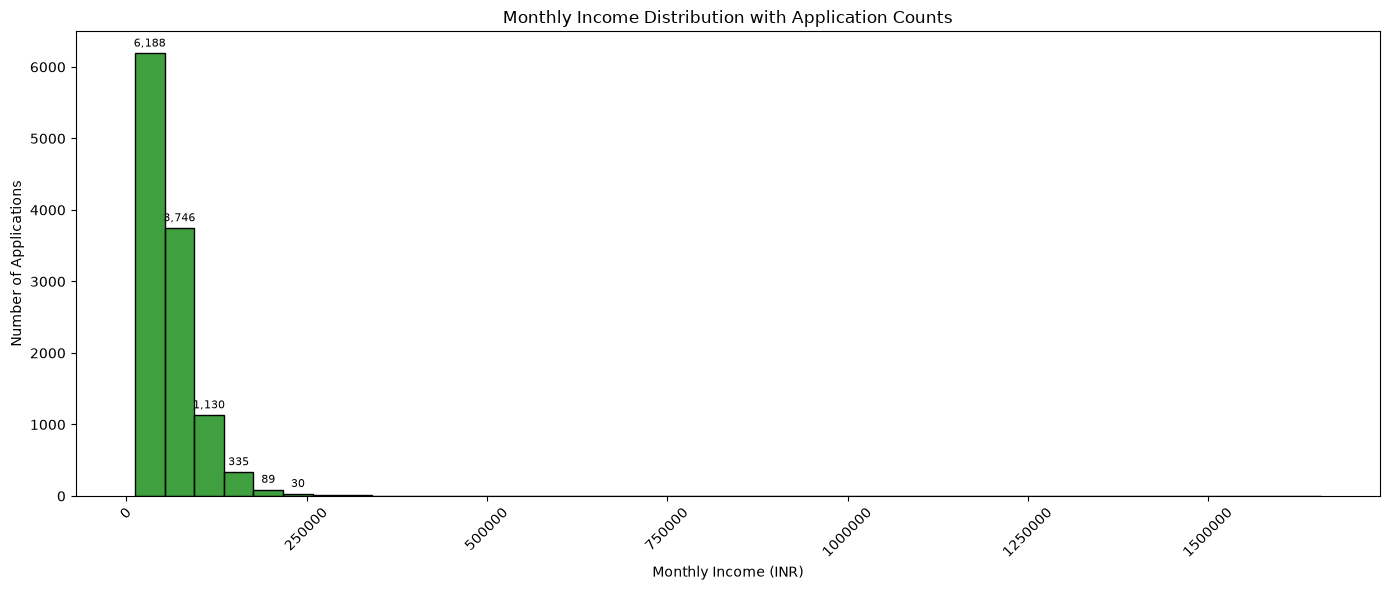

In [78]:
# Plot monthly income distribution with counts
plt.figure(figsize=(14, 6))

ax = sns.histplot(
    data=df_clean,
    x="monthly_income",
    bins=40,
    color="green",
    edgecolor="black"
)

# Add counts above bars with enough observations
for patch in ax.patches:
    height = patch.get_height()

    if height >= 20:
        ax.annotate(
            f"{int(height):,}",
            (
                patch.get_x() + patch.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )

plt.title("Monthly Income Distribution with Application Counts")
plt.xlabel("Monthly Income (INR)")
plt.ylabel("Number of Applications")
plt.ticklabel_format(style="plain", axis="x")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation — Original-Scale Income Histogram

The original-scale histogram shows the distribution of monthly income in rupees. The bars are labelled with application counts when a bin contains at least 20 observations; smaller bins are left unlabelled to avoid visual clutter.

The descriptive statistics already show that the distribution has a long upper tail, with a median of ₹50,500 and a maximum of ₹1,656,000. The original-scale chart helps visualise how the extreme values affect the distribution, although the concentration of lower-income observations may be difficult to inspect when the x-axis spans such a wide range.

I will use the logarithmic-scale histogram as a complementary view rather than as a replacement for the original values.

-------------------------------------------------------------------------------------------------------------------------------

### Examine Monthly Income on a Logarithmic Scale

The maximum monthly income is much larger than the median, so the original-scale chart may make the bulk of the observations appear compressed. A logarithmic x-axis provides a clearer view of how observations are distributed across lower and higher income values.

The bar labels show counts for bins containing at least 20 applications. The log scale changes the spacing of income values on the chart, but it does not modify the underlying income data or resolve whether any individual value is valid.

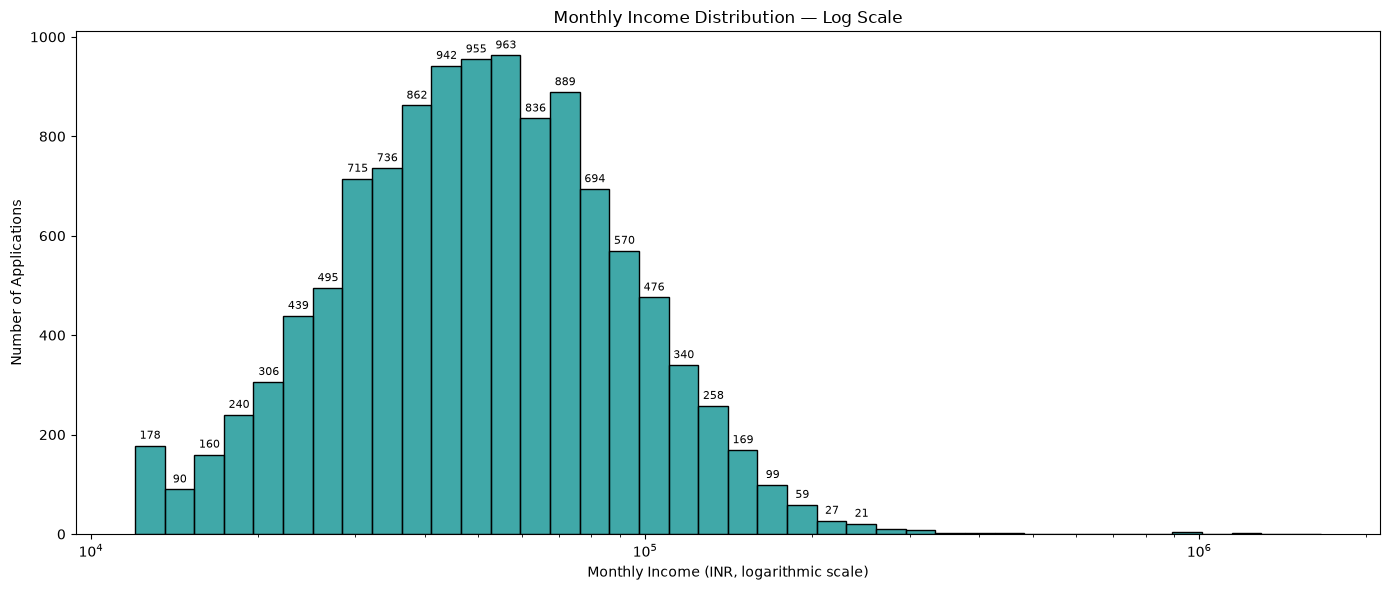

In [79]:
plt.figure(figsize=(14, 6))

ax = sns.histplot(
    data=df_clean,
    x="monthly_income",
    bins=40,
    log_scale=True,
    color="darkcyan",
    edgecolor="black"
)

# Label bars with at least 20 applications
for patch in ax.patches:
    height = patch.get_height()

    if height >= 20:
        ax.annotate(
            f"{int(height):,}",
            (
                patch.get_x() + patch.get_width() / 2,
                height
            ),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points"
        )

plt.title("Monthly Income Distribution — Log Scale")
plt.xlabel("Monthly Income (INR, logarithmic scale)")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

### Interpretation — Logarithmic-Scale Income Histogram

The logarithmic-scale histogram provides a complementary view of the monthly-income distribution, making the spread across lower and higher values easier to inspect than on the original scale.

The two histograms and the descriptive statistics consistently motivate further examination of the upper tail. However, neither visualisation confirms that the highest values are incorrect. Confirmation would require additional evidence, such as checking the source records or verifying the income units.

No income values have been altered based on the plots alone.

----------------------------------------------------------------------------------------------------------------------------------

#### Quantify Potentially Unusual Income Values

I will calculate the number and percentage of applications above selected income thresholds and inspect the relevant records. These thresholds are exploratory checks, not automatic rules for deleting or correcting income values.

The results will help quantify how many applications warrant further investigation.

In [80]:
# Exploratory income thresholds (INR per month)
income_thresholds = [200000, 300000, 500000, 1000000]

threshold_summary = pd.DataFrame({
    "Income_Threshold": income_thresholds,
    "Application_Count": [
        df_clean["monthly_income"].gt(threshold).sum()
        for threshold in income_thresholds
    ]
})

threshold_summary["Percentage"] = (
    threshold_summary["Application_Count"]
    / len(df_clean) * 100
).round(2)

display(threshold_summary)

,Income_Threshold,Application_Count,Percentage
0,200000,93,0.78
1,300000,28,0.23
2,500000,13,0.11
3,1000000,4,0.03


### Findings — Quantifying Potentially Unusual Income Values

The threshold analysis identified the following numbers of applications above selected monthly-income values:

| Monthly income threshold | Applications above threshold | Percentage of all 12,000 applications |
|---|---:|---:|
| ₹200,000 | 93 | 0.78% |
| ₹300,000 | 28 | 0.23% |
| ₹500,000 | 13 | 0.11% |
| ₹1,000,000 | 4 | 0.03% |

Only 28 applications have recorded monthly income above ₹300,000, and just 4 exceed ₹1,000,000. These values are rare within this dataset and can be prioritised for further investigation.

These thresholds are exploratory checks, not official lending limits or proof of incorrect data. I will not automatically remove or cap these records. Any correction would require evidence that a specific value is invalid.

--------------------------------------------------------------------------------------------------------------------

### Check Duplicates and Target Validity

In [81]:
print("Duplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate application IDs:",
    df_clean["application_id"].duplicated().sum()
)

print(
    "Missing decision values:",
    df_clean["decision"].isna().sum()
)

print("\nDecision counts:")
display(
    df_clean["decision"]
    .value_counts(dropna=False)
    .rename_axis("Decision")
    .reset_index(name="Application_Count")
)

# Check for unexpected decision labels
expected_labels = {"Approved", "Declined"}

unexpected_labels = (
    set(df_clean["decision"].dropna().unique())
    - expected_labels
)

print("Unexpected decision labels:", unexpected_labels)

Duplicate rows: 0
Duplicate application IDs: 0
Missing decision values: 0

Decision counts:


,Decision,Application_Count
0,Approved,6353
1,Declined,5647


Unexpected decision labels: set()


### Findings — Duplicate Records and Target Validity

The quality checks found **zero duplicate rows**, **zero duplicate application IDs**, and **zero missing values in the `decision` column**. The target contains only the expected labels, `Approved` and `Declined`; the unexpected-label check returned an empty set.

The dataset contains 6,353 Approved applications and 5,647 Declined applications. Since the checks did not identify any duplicate or invalid target records, no rows need to be removed on these grounds.

The `application_id` field will remain available for record tracking and auditing, but it will be excluded from model features because it is an identifier rather than an intended applicant-risk predictor.

-----------------------------------------------------------------------------------------------------------------------------------

### Calculate the Overall Approval Rate

The overall approval rate is the proportion of applications historically approved by the credit team, while the decline rate is the proportion historically declined. These rates establish the baseline distribution of the target before model training.

I will calculate the application count and percentage for each decision category. The resulting proportions will help determine whether the target is heavily imbalanced and provide a reference point for evaluating the classification model.

In [82]:
# Calculate decision counts
decision_counts = (
    df_clean["decision"]
    .value_counts()
    .reindex(["Approved", "Declined"], fill_value=0)
)

# Calculate decision percentages
decision_percentages = (
    decision_counts / len(df_clean) * 100
).round(2)

# Create summary table
decision_summary = pd.DataFrame({
    "Application_Count": decision_counts,
    "Percentage": decision_percentages
})

display(decision_summary)

# Calculate approval and decline rates
approval_rate = (
    df_clean["decision"].eq("Approved").mean() * 100
)

decline_rate = (
    df_clean["decision"].eq("Declined").mean() * 100
)

print(f"Overall approval rate: {approval_rate:.2f}%")
print(f"Overall decline rate: {decline_rate:.2f}%")

,Application_Count,Percentage
decision,,
Approved,6353,52.94
Declined,5647,47.06


Overall approval rate: 52.94%
Overall decline rate: 47.06%


### Findings — Overall Historical Decision Rates

Of the 12,000 applications, **6,353 were Approved (52.94%)** and **5,647 were Declined (47.06%)**. The overall approval rate is therefore 52.94%, and the overall decline rate is 47.06%.

The two classes are reasonably balanced in terms of their overall proportions; neither class overwhelmingly dominates the dataset. This is useful for classification modelling, although class balance alone does not establish model quality.

Because a false decline can affect an applicant who was historically approved, the model must be evaluated using the confusion matrix, precision, recall, and the assignment's threshold risk limit—not accuracy alone.

--------------------------------------------------------------------------------------------------------------------------

### Visualise Historical Loan Decisions

I will use a bar chart to compare the counts of Approved and Declined applications. Each bar displays its count and percentage of the 12,000 applications so that the target distribution can be checked visually against the summary table.

The chart provides a simple visual confirmation of the overall approval and decline rates before proceeding to feature engineering and model development.

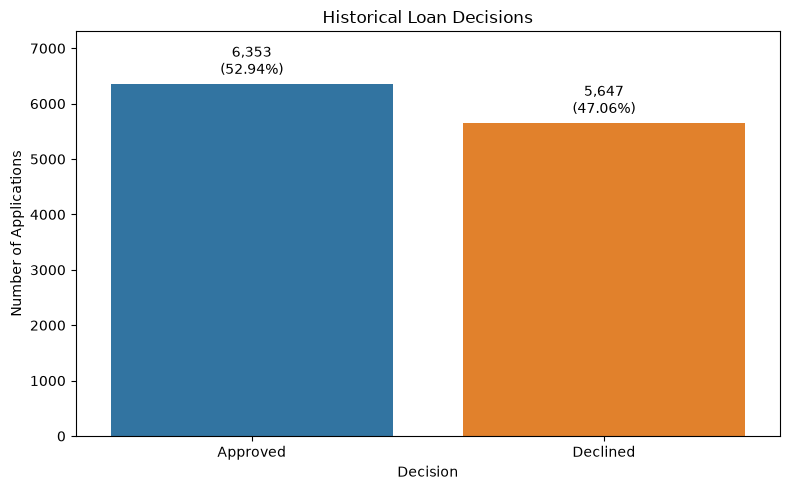

In [83]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="decision",
    order=["Approved", "Declined"],
    hue="decision",
    legend=False
)

# Add counts and percentages above the bars
total_applications = len(df_clean)

for patch in ax.patches:
    count = int(patch.get_height())
    percentage = count / total_applications * 100

    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        (
            patch.get_x() + patch.get_width() / 2,
            patch.get_height()
        ),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Historical Loan Decisions")
plt.xlabel("Decision")
plt.ylabel("Number of Applications")
plt.ylim(0, max(decision_counts) * 1.15)
plt.tight_layout()
plt.show()

### Interpretation — Historical Loan Decisions

The chart shows 6,353 Approved applications (52.94%) and 5,647 Declined applications (47.06%). The difference between the two categories is relatively small, which agrees with the calculated summary table.

This confirms that the target is not severely imbalanced at the overall dataset level. Nevertheless, the business objective is safe workload reduction, so model performance must be assessed by examining which types of applications are incorrectly classified and how many cases can be routed safely under the specified risk limits.

------------------------------------------------------------------------------------------------------------

### Convert Application Date to Datetime

The `application_date` column represents the date on which each application was received. I will convert it to a datetime data type and check for invalid or missing dates introduced by the conversion.

This ensures that the date field has an appropriate data type for chronological analysis. Although `application_date` is not permitted as a model feature in this use case, validating it helps confirm the consistency of the source data.

In [84]:
# Convert dates to datetime
df_clean["application_date"] = pd.to_datetime(
    df_clean["application_date"],
    errors="coerce"
)

print(
    "Application date data type:",
    df_clean["application_date"].dtype
)

print(
    "Invalid or missing dates:",
    df_clean["application_date"].isna().sum()
)

print(
    "Earliest application date:",
    df_clean["application_date"].min()
)

print(
    "Latest application date:",
    df_clean["application_date"].max()
)

Application date data type: datetime64[us]
Invalid or missing dates: 0
Earliest application date: 2026-04-01 00:00:00
Latest application date: 2026-09-30 00:00:00


### Findings — Application Date Validation

The `application_date` column was successfully converted to `datetime64[us]`. The conversion produced **zero invalid or missing dates**.

The earliest application date is **1 April 2026**, and the latest is **30 September 2026**, matching the expected six-month observation period from April through September 2026.

The date field is now stored in an appropriate datetime format. It will remain excluded from the model features as required by the assignment.

----------------------------------------------------------------------------------------------------------------------------

### Final Data-Quality Verification

I will perform a final check of the working DataFrame to confirm its dimensions, data types, remaining missing values, and duplicate counts. This provides a concise record of the dataset's current state after the inspection and date conversion.

Missing values that have not yet been imputed will remain visible and documented. The income anomaly investigation is also considered unresolved until supporting evidence justifies a correction.

In [85]:
print("Dataset shape:", df_clean.shape)

print("\nData types:")
display(df_clean.dtypes.rename("Data_Type").to_frame())

print("\nRemaining missing values:")
remaining_missing = (
    df_clean.isnull()
    .sum()
    .rename("Missing_Count")
)

display(
    remaining_missing[remaining_missing > 0].to_frame()
)

print("\nDuplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate application IDs:",
    df_clean["application_id"].duplicated().sum()
)

Dataset shape: (12000, 19)

Data types:


,Data_Type
application_id,str
application_date,datetime64[us]
age,int64
gender,str
city,str
city_tier,int64
employment_type,str
years_in_current_job,float64
monthly_income,float64
existing_emi,float64



Remaining missing values:


,Missing_Count
monthly_income,441
credit_score,1039



Duplicate rows: 0
Duplicate application IDs: 0


### Findings — Final Data-Quality Verification

The final inspection confirms that the working dataset contains **12,000 rows and 19 columns**. The application date is stored as `datetime64[us]`, and the remaining column types are consistent with the numerical and categorical information they represent.

Two columns still contain missing values: `monthly_income` has **441 missing values**, and `credit_score` has **1,039 missing values**. The dataset contains **zero duplicate rows and zero duplicate application IDs**.

These remaining null values are intentional at this stage of the workflow: they have been investigated and documented, but not globally imputed in the original working DataFrame. Missing income will be handled using training-data-derived employment-type medians, and missing credit scores will be handled during model preprocessing while preserving the NTC indicator.

The unusually high income values also remain unchanged because the available evidence does not establish that they are errors.

In [86]:
# Step 5.1: Final validation checks

expected_columns = 19
expected_rows = 12000
expected_decisions = {"Approved", "Declined"}

validation_results = {
    "Expected dataset shape": (
        df_clean.shape == (expected_rows, expected_columns)
    ),
    "No duplicate rows": (
        df_clean.duplicated().sum() == 0
    ),
    "No duplicate application IDs": (
        df_clean["application_id"].duplicated().sum() == 0
    ),
    "No missing application IDs": (
        df_clean["application_id"].isna().sum() == 0
    ),
    "No missing target labels": (
        df_clean["decision"].isna().sum() == 0
    ),
    "Only expected target labels": (
        set(df_clean["decision"].unique()) == expected_decisions
    ),
    "Application dates converted": (
        pd.api.types.is_datetime64_any_dtype(
            df_clean["application_date"]
        )
    ),
    "Missing scores have zero credit history": (
        df_clean.loc[
            df_clean["credit_score"].isna(),
            "credit_history_months"
        ].eq(0).all()
    ),
    "Missing income count matches inspection": (
        df_clean["monthly_income"].isna().sum() == 441
    ),
    "Missing credit score count matches inspection": (
        df_clean["credit_score"].isna().sum() == 1039
    )
}

validation_summary = pd.DataFrame({
    "Validation": list(validation_results.keys()),
    "Passed": list(validation_results.values())
})

display(validation_summary)

print(
    f"\nOverall result: "
    f"{sum(validation_results.values())}/"
    f"{len(validation_results)} checks passed."
)

if not all(validation_results.values()):
    print("Review the failed checks before marking Step 5.1 complete.")
else:
    print("All validation checks passed.")

,Validation,Passed
0,Expected dataset shape,True
1,No duplicate rows,True
2,No duplicate application IDs,True
3,No missing application IDs,True
4,No missing target labels,True
5,Only expected target labels,True
6,Application dates converted,True
7,Missing scores have zero credit history,True
8,Missing income count matches inspection,True
9,Missing credit score count matches inspection,True



Overall result: 10/10 checks passed.
All validation checks passed.


## Step 5.1 — Conclusion: Load, Inspect and Clean

The dataset contains **12,000 loan applications and 19 columns**, covering the period from 1 April 2026 to 30 September 2026. The data-quality checks found no duplicate rows, duplicate application IDs, missing application IDs, missing decision labels, or unexpected decision categories. The historical target contains 6,353 Approved applications (52.94%) and 5,647 Declined applications (47.06%).

The missing-value investigation identified 441 missing monthly-income values (3.68%) and 1,039 missing credit scores (8.66%). Missing income is concentrated among Business Owners (227 records) and Self-Employed Professionals (154 records), supporting employment-type-specific median imputation learned from training data. All applicants with missing credit scores have zero months of credit history, so they will be retained and identified through the `is_ntc` feature rather than dropped or assigned a score of zero.

The income analysis found a median of ₹50,500 and a maximum of ₹1,656,000. Although the extreme upper-tail values warrant investigation, they will not be automatically changed without evidence of incorrect recording. The original working data retains the documented nulls so that imputation can be performed appropriately during model preparation.

Overall, Step 5.1 establishes the dataset's structure, target distribution, missing-value patterns, and potential income anomalies. These findings provide the basis for examining historical approval patterns in Step 5.2 and engineering risk-related features in Step 5.3. The final validation completed successfully, with **10 out of 10 checks passed**.

## 5.2  What drives approval today?

In [87]:
# Step 5.2.1: Create credit-score bands

score_bins = [-np.inf, 600, 650, 700, 750, 800, np.inf]

score_labels = [
    "Below 600",
    "600–649",
    "650–699",
    "700–749",
    "750–799",
    "800+"
]

df_clean["credit_score_band"] = pd.cut(
    df_clean["credit_score"],
    bins=score_bins,
    labels=score_labels,
    right=False
)

# Add a separate category for applicants without a credit score
df_clean["credit_score_band"] = (
    df_clean["credit_score_band"]
    .cat.add_categories(["No score"])
    .fillna("No score")
)

# Display application counts in each band
score_band_counts = (
    df_clean["credit_score_band"]
    .value_counts()
    .reindex(score_labels + ["No score"], fill_value=0)
    .rename_axis("Credit_Score_Band")
    .reset_index(name="Application_Count")
)

display(score_band_counts)

# Verify that every application belongs to exactly one band
print("Total applications across bands:", score_band_counts["Application_Count"].sum())
print("Total dataset applications:", len(df_clean))

,Credit_Score_Band,Application_Count
0,Below 600,246
1,600–649,933
2,650–699,2529
3,700–749,3377
4,750–799,2526
5,800+,1350
6,No score,1039


Total applications across bands: 12000
Total dataset applications: 12000


### Step 5.2.1 — Create Credit-Score Bands

**Objective:** Categorize applicants into the six required credit-score ranges and a separate `No score` category.

The `credit_score` column is divided into the following groups: Below 600, 600–649, 650–699, 700–749, 750–799, and 800+. Applicants with missing credit scores are assigned to the `No score` group instead of being removed or treated as having a score of zero.

**Findings and interpretation:**

- The dataset contains **12,000 applications**, and the counts across all seven groups sum to 12,000.
- The largest group is the 700–749 band, with **3,377 applications**.
- The smallest group is the Below 600 band, with **246 applications**.
- There are **1,039 applicants without a recorded credit score**.

This grouping allows us to compare historical approval patterns across score ranges while keeping applicants without a recorded score separate.

In [88]:
# Step 5.2.2: Calculate approval rates by credit-score band

score_analysis = (
    df_clean.groupby("credit_score_band", observed=False)
    .agg(
        Total_Applications=("decision", "size"),
        Approved_Applications=(
            "decision",
            lambda s: s.eq("Approved").sum()
        ),
        Declined_Applications=(
            "decision",
            lambda s: s.eq("Declined").sum()
        )
    )
    .reindex(score_labels + ["No score"])
    .reset_index()
)

score_analysis["Approval_Rate_Pct"] = (
    score_analysis["Approved_Applications"]
    / score_analysis["Total_Applications"].replace(0, np.nan)
    * 100
).round(2)

score_analysis["Decline_Rate_Pct"] = (
    score_analysis["Declined_Applications"]
    / score_analysis["Total_Applications"].replace(0, np.nan)
    * 100
).round(2)

display(score_analysis)

,credit_score_band,Total_Applications,Approved_Applications,Declined_Applications,Approval_Rate_Pct,Decline_Rate_Pct
0,Below 600,246,5,241,2.03,97.97
1,600–649,933,30,903,3.22,96.78
2,650–699,2529,822,1707,32.50,67.50
3,700–749,3377,1836,1541,54.37,45.63
4,750–799,2526,1950,576,77.20,22.80
5,800+,1350,1150,200,85.19,14.81
6,No score,1039,560,479,53.90,46.10


### Step 5.2.2 — Calculate Historical Approval Rates by Credit-Score Band

**Objective:** Calculate the total, approved, and declined applications and the corresponding approval and decline rates for each credit-score band.

**Findings and interpretation:**

- The approval rate for applicants scoring below 600 is **2.03%**, with 5 approvals out of 246 applications.
- Applicants scoring 600–649 have an approval rate of **3.22%**, with 30 approvals out of 933 applications.
- The approval rate increases to **32.50%** for scores between 650 and 699 and **54.37%** for scores between 700 and 749.
- Applicants scoring 750–799 have an approval rate of **77.20%**, while those scoring 800 or above have the highest rate at **85.19%**.
- Applicants in the `No score` category have an approval rate of **53.90%**, with 560 approvals out of 1,039 applications.

Overall, the results show a strong positive association between observed credit-score bands and historical approval rates. The very low approval rates below 650 suggest a possible historical credit-score threshold, although the data does not establish a formal cutoff.

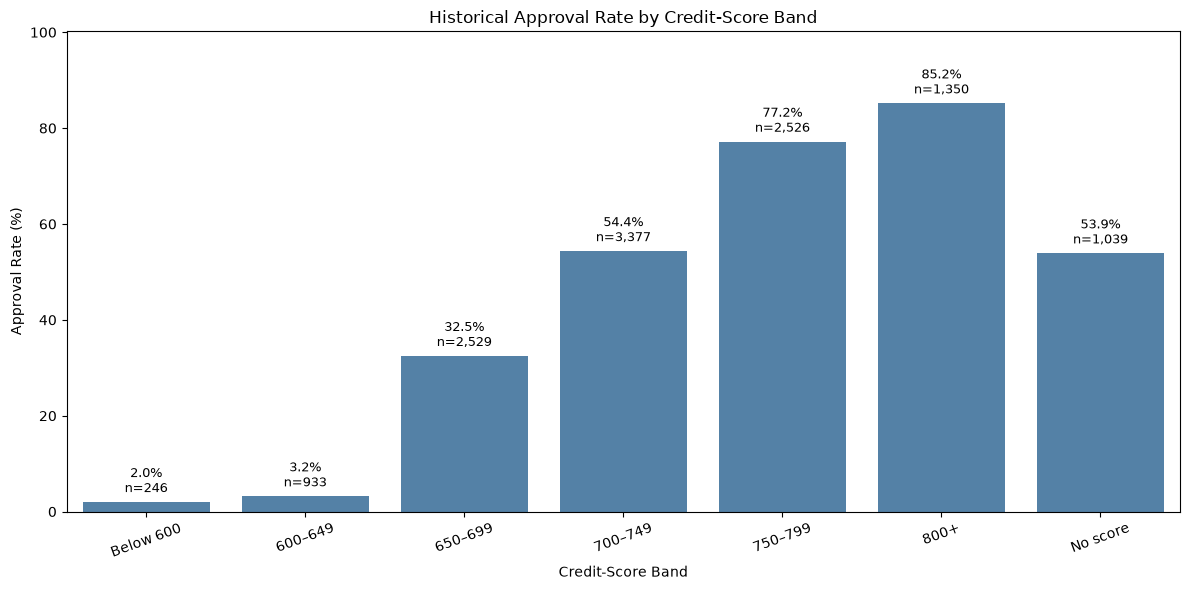

In [89]:
# Step 5.2.3: Plot approval rates by credit-score band

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=score_analysis,
    x="credit_score_band",
    y="Approval_Rate_Pct",
    color="steelblue"
)

for i, row in score_analysis.iterrows():
    if pd.notna(row["Approval_Rate_Pct"]):
        ax.annotate(
            f'{row["Approval_Rate_Pct"]:.1f}%\n'
            f'n={int(row["Total_Applications"]):,}',
            (i, row["Approval_Rate_Pct"]),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.title("Historical Approval Rate by Credit-Score Band")
plt.xlabel("Credit-Score Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(
    0,
    min(110, score_analysis["Approval_Rate_Pct"].max() + 15)
)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Step 5.2.3 — Visualise Approval Rates by Credit-Score Band

**Objective:** Use a bar chart to compare historical approval rates across credit-score bands. Each bar displays the approval percentage and the number of applications in that group.

**Findings and interpretation:**

The chart shows that approval rates generally increase as credit scores rise. The two lowest bands have approval rates of only **2.03% and 3.22%**, followed by a substantial increase in the 650–699 band to 32.50%.

The highest approval rate is observed in the 800+ band at **85.19%**. The `No score` group has an approval rate of **53.90%**, which is much higher than the rates for applicants scoring below 650.

This visual pattern suggests that the bank's historical decisions strongly distinguish applicants with very low credit scores from applicants with higher scores or no recorded score. However, approval rates alone cannot establish the bank's formal policy or the applicants' future repayment performance.

In [90]:
# Step 5.2.4: Calculate approval rates by employment type

employment_analysis = (
    df_clean.groupby("employment_type", dropna=False)
    .agg(
        Total_Applications=("decision", "size"),
        Approved_Applications=(
            "decision",
            lambda s: s.eq("Approved").sum()
        ),
        Declined_Applications=(
            "decision",
            lambda s: s.eq("Declined").sum()
        )
    )
    .reset_index()
)

employment_analysis["Approval_Rate_Pct"] = (
    employment_analysis["Approved_Applications"]
    / employment_analysis["Total_Applications"]
    * 100
).round(2)

employment_analysis["Decline_Rate_Pct"] = (
    employment_analysis["Declined_Applications"]
    / employment_analysis["Total_Applications"]
    * 100
).round(2)

employment_analysis = employment_analysis.sort_values(
    "Approval_Rate_Pct",
    ascending=False
)

display(employment_analysis)

,employment_type,Total_Applications,Approved_Applications,Declined_Applications,Approval_Rate_Pct,Decline_Rate_Pct
2,Salaried,7057,4119,2938,58.37,41.63
0,Business Owner,1749,895,854,51.17,48.83
3,Self-Employed Professional,1428,722,706,50.56,49.44
1,Gig / Contract,1766,617,1149,34.94,65.06


### Step 5.2.4 — Calculate Historical Approval Rates by Employment Type

**Objective:** Compare total applications, approved applications, declined applications, and approval and decline rates across employment categories.

**Findings and interpretation:**

- **Salaried:** 4,119 of 7,057 applications were approved, resulting in an approval rate of **58.37%**.
- **Business Owner:** 895 of 1,749 applications were approved, resulting in an approval rate of **51.17%**.
- **Self-Employed Professional:** 722 of 1,428 applications were approved, resulting in an approval rate of **50.56%**.
- **Gig / Contract:** 617 of 1,766 applications were approved, resulting in the lowest approval rate of **34.94%**.

Salaried applicants have the highest historical approval rate, while Gig / Contract applicants have the lowest. The difference is **23.43 percentage points**.

These differences indicate that historical approval outcomes vary by employment category. However, employment type alone may not explain the differences; income, credit score, existing financial commitments, and other applicant characteristics may also contribute.

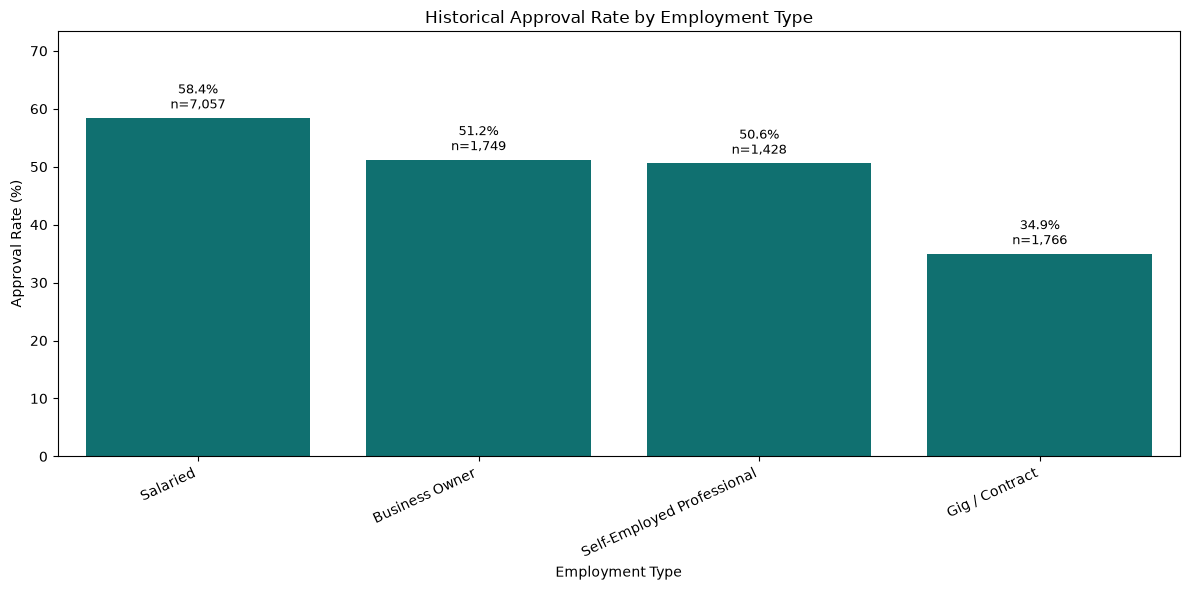

In [91]:
# Step 5.2.5: Plot approval rates by employment type

employment_plot = employment_analysis.reset_index(drop=True)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=employment_plot,
    x="employment_type",
    y="Approval_Rate_Pct",
    color="teal"
)

for i, row in employment_plot.iterrows():
    ax.annotate(
        f'{row["Approval_Rate_Pct"]:.1f}%\n'
        f'n={int(row["Total_Applications"]):,}',
        (i, row["Approval_Rate_Pct"]),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.title("Historical Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.ylim(
    0,
    min(110, employment_plot["Approval_Rate_Pct"].max() + 15)
)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Step 5.2.5 — Visualise Approval Rates by Employment Type

**Objective:** Display the historical approval rate for each employment category using a bar chart. The percentage and application count are shown above each bar to support clear comparisons.

**Findings and interpretation:**

The chart confirms that salaried applicants have the highest historical approval rate at **58.37%**, followed by Business Owners at **51.17%** and Self-Employed Professionals at **50.56%**. Gig / Contract applicants have the lowest approval rate at **34.94%**.

The lower approval rate for Gig / Contract applicants suggests that historical lending outcomes differ across employment categories. This difference warrants further investigation, particularly to determine whether it is associated with differences in income stability, credit history, financial obligations, or other relevant characteristics.

The chart identifies an association, not a causal relationship or proof of unfair treatment.

In [92]:
# Step 5.2.6: Validate approval analysis

print("Credit-score band checks")
print(
    "Applications accounted for:",
    score_analysis["Total_Applications"].sum()
)
print("Dataset applications:", len(df_clean))

print(
    "Approved count matches dataset:",
    score_analysis["Approved_Applications"].sum()
    == df_clean["decision"].eq("Approved").sum()
)

print(
    "Declined count matches dataset:",
    score_analysis["Declined_Applications"].sum()
    == df_clean["decision"].eq("Declined").sum()
)

print("\nEmployment-type checks")
print(
    "Applications accounted for:",
    employment_analysis["Total_Applications"].sum()
)
print("Dataset applications:", len(df_clean))

print(
    "Employment approval counts match dataset:",
    employment_analysis["Approved_Applications"].sum()
    == df_clean["decision"].eq("Approved").sum()
)

print(
    "Employment decline counts match dataset:",
    employment_analysis["Declined_Applications"].sum()
    == df_clean["decision"].eq("Declined").sum()
)

Credit-score band checks
Applications accounted for: 12000
Dataset applications: 12000
Approved count matches dataset: True
Declined count matches dataset: True

Employment-type checks
Applications accounted for: 12000
Dataset applications: 12000
Employment approval counts match dataset: True
Employment decline counts match dataset: True


### Step 5.2.6 — Validate Approval Analysis

**Objective:** Verify that all applications are represented in the credit-score and employment-type analyses, and confirm that the approved and declined application counts match the original dataset.

**Validation results:**

- The credit-score band analysis accounts for all **12,000 applications**.
- The employment-type analysis also accounts for all **12,000 applications**.
- The total approved counts match the original dataset.
- The total declined counts match the original dataset.
- All validation checks returned `True`.

**Interpretation:**

The validation results confirm that both analyses account for the complete dataset and that the approval and decline counts reconcile with the original decision labels. This supports the reliability of the calculations used in the tables and visualisations.

----------------------------------------------------------------------------------------------------------------

### 1\. Is there a score below which applications are almost never approved?

Yes. Applicants with credit scores below 650 are almost never approved. The approval rate is only 2.03% for scores below 600 and 3.22% for scores between 600 and 649. This suggests that the bank follows a strong historical preference for applicants with credit scores of at least 650, although it is not an absolute cutoff because some applicants below 650 were approved.

### 2\. What does this tell you about the bank's unwritten credit policy?

The results suggest that the bank's historical decisions follow an implicit credit-score threshold around 650. Applicants below this level are overwhelmingly declined, while approval rates increase substantially at higher scores. However, this is an observed pattern, not proof of a formal policy.

### 3\. How do applicants with no credit score fare compared to scored applicants?

Applicants with no recorded credit score have an approval rate of 53.90% (560 out of 1,039 applications). This is much higher than the 3.22% approval rate for applicants scoring 600–649 and close to the 54.37% rate for applicants scoring 700–749. Since the missing-score applicants have zero credit-history months, they may be new-to-credit applicants. The results suggest that the bank treats applicants without a recorded score differently from those with very low scores, so missing credit scores should not automatically be considered evidence of poor creditworthiness.

----------------------------------------------------------------------------------------------------------------

### Step 5.2 — Overall Conclusion: What Drives Historical Approval?

The analysis reveals a strong association between credit score and historical loan approval. Applicants scoring below 650 have very low approval rates of **2.03% and 3.22%**, suggesting a possible historical credit-score threshold, although 35 applicants in these bands were approved. Applicants with no recorded credit score have a substantially higher approval rate of **53.90%**, indicating that missing scores should not automatically be treated as poor scores. Approval rates also vary by employment type: salaried applicants have the highest rate at **58.37%**, while Gig / Contract applicants have the lowest at **34.94%**. These patterns provide useful context for feature engineering and model development, but historical decisions do not necessarily represent actual creditworthiness or future repayment outcomes. The next step is to investigate financial-obligation features and their relationship with historical approval decisions.

------------------------------------------------------------------------------------------------------------------

## 5.3  Engineer the affordability features

In [93]:
# Step 5.3.1: Feature engineering

# 1. Fixed Obligation to Income Ratio (FOIR)
df_clean["foir"] = (
    (df_clean["existing_emi"] + df_clean["proposed_emi"])
    / df_clean["monthly_income"]
)

# 2. Loan-to-Income Ratio
df_clean["loan_to_income"] = (
    df_clean["loan_amount"]
    / (df_clean["monthly_income"] * 12)
)

# 3. New-to-Credit indicator
df_clean["is_ntc"] = (
    df_clean["credit_score"].isna().astype(int)
)

# Inspect newly created features
display(
    df_clean[
        [
            "monthly_income",
            "existing_emi",
            "proposed_emi",
            "loan_amount",
            "credit_score",
            "foir",
            "loan_to_income",
            "is_ntc"
        ]
    ].head(10)
)

,monthly_income,existing_emi,proposed_emi,loan_amount,credit_score,foir,loan_to_income,is_ntc
0,95000.0,23500.0,6600.0,240000.0,784.0,0.316842,0.210526,0
1,43000.0,8500.0,5000.0,145000.0,790.0,0.313953,0.281008,0
2,35000.0,3500.0,11800.0,345000.0,718.0,0.437143,0.821429,0
3,44500.0,0.0,4600.0,135000.0,NaN,0.103371,0.252809,1
4,83500.0,6000.0,33600.0,700000.0,700.0,0.474251,0.698603,0
5,105000.0,6000.0,12100.0,355000.0,808.0,0.172381,0.281746,0
6,30000.0,2000.0,14800.0,165000.0,792.0,0.560000,0.458333,0
7,NaN,16500.0,37700.0,785000.0,634.0,NaN,NaN,0
8,74500.0,19000.0,21800.0,455000.0,738.0,0.547651,0.508949,0
9,NaN,5500.0,26700.0,780000.0,687.0,NaN,NaN,0


### Step 5.3.1 — Feature Engineering

**Objective:** Create three additional features to capture applicants' financial obligations and credit-history status.

- `foir`: Calculated as the sum of existing EMI and proposed EMI divided by monthly income.
- `loan_to_income`: Calculated as the requested loan amount divided by annualized monthly income.
- `is_ntc`: Assigned 1 when the credit score is missing and 0 otherwise.

**Findings and interpretation:**

The three features were created successfully. The `foir` and `loan_to_income` values are missing for applicants whose monthly income is unavailable. This is expected because both calculations depend on monthly income.

The `is_ntc` feature distinguishes applicants without a recorded credit score from applicants with an observed score. This is important because missing credit scores should not automatically be interpreted as poor creditworthiness.

Missing financial values will be handled during model preprocessing using a documented, leakage-safe imputation strategy.

In [94]:
# Step 5.3.2: Validate engineered features

feature_columns = ["foir", "loan_to_income", "is_ntc"]

feature_validation = pd.DataFrame({
    "Missing_Count": df_clean[feature_columns].isna().sum(),
    "Infinite_Count": [
        np.isinf(df_clean[col].dropna()).sum()
        if pd.api.types.is_numeric_dtype(df_clean[col])
        else 0
        for col in feature_columns
    ],
    "Unique_Values": df_clean[feature_columns].nunique()
})

display(feature_validation)

print("\nFOIR summary:")
display(df_clean["foir"].describe().to_frame())

print("\nLoan-to-income summary:")
display(df_clean["loan_to_income"].describe().to_frame())

print("\nNTC counts:")
display(
    df_clean["is_ntc"]
    .value_counts()
    .sort_index()
    .rename_axis("is_ntc")
    .reset_index(name="Application_Count")
)

,Missing_Count,Infinite_Count,Unique_Values
foir,441,0,8145
loan_to_income,441,0,5566
is_ntc,0,0,2



FOIR summary:


,foir
count,11559.000000
mean,0.355792
std,0.198464
min,0.004798
25%,0.215162
50%,0.316230
75%,0.448795
max,1.505164



Loan-to-income summary:


,loan_to_income
count,11559.000000
mean,0.527391
std,0.212983
min,0.014731
25%,0.347222
50%,0.519126
75%,0.698043
max,1.084656



NTC counts:


,is_ntc,Application_Count
0,0,10961
1,1,1039


### Step 5.3.2 — Validate Engineered Features

**Objective:** Examine missing values, infinite values, unique values, and descriptive statistics for the newly created features.

**Findings and interpretation:**

The `foir` and `loan_to_income` features each contain **441 missing values**, corresponding to applications with missing monthly income. Neither feature contains infinite values.

The FOIR distribution has a mean of approximately **35.58%** and a median of **31.62%**. Its maximum is approximately **150.52%**, indicating that some applicants' combined existing and proposed EMI obligations exceed their recorded monthly income.

The `loan_to_income` feature has a mean of approximately **0.5274** and a median of **0.5191**. Its maximum is approximately **1.0847**, meaning the requested loan amount exceeds annualized recorded income for at least some applicants.

The `is_ntc` feature contains only two values, 0 and 1, with **10,961 applicants having a recorded credit score and 1,039 having no recorded score**.

These results indicate that the features were calculated without introducing infinite values. The high financial ratios should be investigated rather than automatically removed or capped.

In [95]:
# Step 5.3.3: Create FOIR bands

foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]

foir_labels = [
    "Below 30%",
    "30–40%",
    "40–50%",
    "50–55%",
    "Above 55%"
]

df_clean["foir_band"] = pd.cut(
    df_clean["foir"],
    bins=foir_bins,
    labels=foir_labels,
    right=False
)

foir_band_counts = (
    df_clean["foir_band"]
    .value_counts()
    .reindex(foir_labels, fill_value=0)
    .rename_axis("FOIR_Band")
    .reset_index(name="Application_Count")
)

# Show missing FOIR values separately
missing_foir_count = df_clean["foir"].isna().sum()

display(foir_band_counts)
print("Applications with missing FOIR:", missing_foir_count)

,FOIR_Band,Application_Count
0,Below 30%,5290
1,30–40%,2422
2,40–50%,1713
3,50–55%,519
4,Above 55%,1615


Applications with missing FOIR: 441


### Step 5.3.3 — Create FOIR Bands

**Objective:** Categorize applicants into the five FOIR bands specified in the assignment: Below 30%, 30–40%, 40–50%, 50–55%, and Above 55%.

**Findings and interpretation:**

Among the 12,000 applications, **11,559 have valid FOIR values**, while 441 have missing FOIR because monthly income is unavailable.

The distribution across the five bands is:

- Below 30%: **5,290 applications**
- 30–40%: **2,422 applications**
- 40–50%: **1,713 applications**
- 50–55%: **519 applications**
- Above 55%: **1,615 applications**

The largest group is Below 30%, containing 5,290 applications. The missing FOIR records are kept separate rather than being incorrectly assigned to a low-obligation category.

In [96]:
# Step 5.3.4: Approval analysis by FOIR band

foir_analysis = (
    df_clean.groupby("foir_band", observed=False)
    .agg(
        Total_Applications=("decision", "size"),
        Approved_Applications=(
            "decision",
            lambda s: s.eq("Approved").sum()
        ),
        Declined_Applications=(
            "decision",
            lambda s: s.eq("Declined").sum()
        )
    )
    .reindex(foir_labels)
    .reset_index()
)

foir_analysis["Approval_Rate_Pct"] = (
    foir_analysis["Approved_Applications"]
    / foir_analysis["Total_Applications"].replace(0, np.nan)
    * 100
).round(2)

foir_analysis["Decline_Rate_Pct"] = (
    foir_analysis["Declined_Applications"]
    / foir_analysis["Total_Applications"].replace(0, np.nan)
    * 100
).round(2)

display(foir_analysis)

,foir_band,Total_Applications,Approved_Applications,Declined_Applications,Approval_Rate_Pct,Decline_Rate_Pct
0,Below 30%,5290,3477,1813,65.73,34.27
1,30–40%,2422,1435,987,59.25,40.75
2,40–50%,1713,823,890,48.04,51.96
3,50–55%,519,168,351,32.37,67.63
4,Above 55%,1615,229,1386,14.18,85.82


### Step 5.3.4 — Calculate Historical Approval Rates by FOIR Band

**Objective:** Calculate total applications, approved applications, declined applications, and approval and decline rates for each FOIR category.

**Findings and interpretation:**

The historical approval rate decreases as FOIR increases:

- Below 30%: **65.73%**
- 30–40%: **59.25%**
- 40–50%: **48.04%**
- 50–55%: **32.37%**
- Above 55%: **14.18%**

The highest approval rate occurs in the Below 30% band, while the lowest occurs in the Above 55% band.

This pattern suggests a strong negative association between FOIR and historical approval. Applicants with a greater proportion of their income committed to EMI obligations were less likely to be approved in the historical dataset.

However, these findings show an association rather than causation. Other applicant characteristics and historical credit policies may also influence the observed decisions.

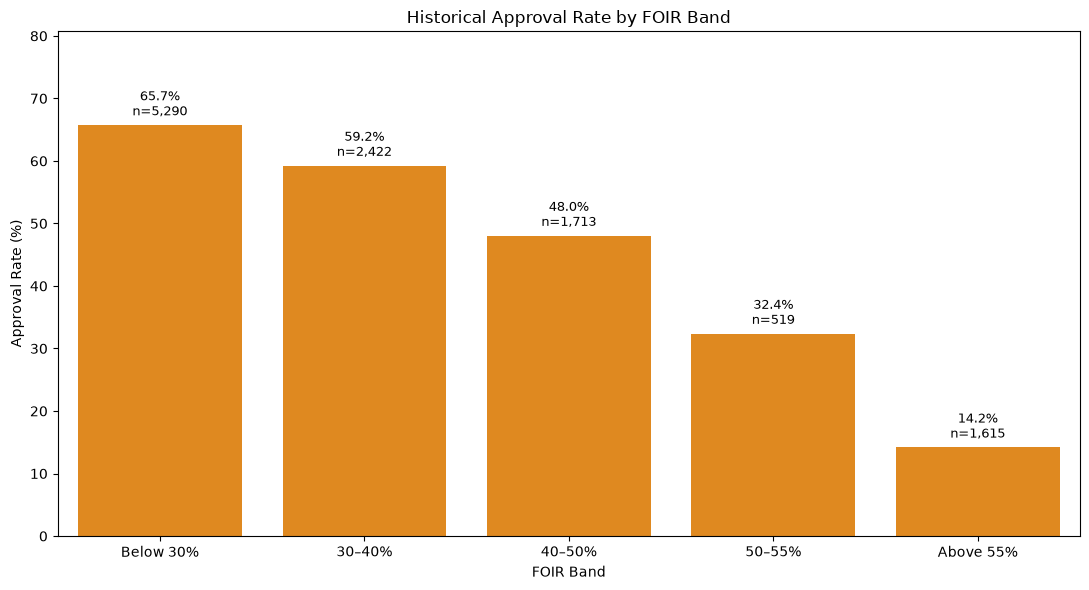

In [97]:
# Step 5.3.5: Visualize approval rates by FOIR band

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=foir_analysis,
    x="foir_band",
    y="Approval_Rate_Pct",
    color="darkorange"
)

for i, row in foir_analysis.iterrows():
    if pd.notna(row["Approval_Rate_Pct"]):
        ax.annotate(
            f'{row["Approval_Rate_Pct"]:.1f}%\n'
            f'n={int(row["Total_Applications"]):,}',
            (i, row["Approval_Rate_Pct"]),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.title("Historical Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(
    0,
    min(110, foir_analysis["Approval_Rate_Pct"].max() + 15)
)
plt.tight_layout()
plt.show()

### Step 5.3.5 — Visualise Approval Rates by FOIR Band

**Objective:** Visualize historical approval rates across the five FOIR categories, displaying the approval percentage and application count above each bar.

**Findings and interpretation:**

The bar chart confirms a consistent decline in historical approval rates as FOIR increases. Approval falls from **65.73%** for applicants with FOIR below 30% to **14.18%** for applicants with FOIR above 55%.

The decline is particularly notable in the higher FOIR bands: approval falls from 48.04% in the 40–50% band to 32.37% in the 50–55% band, followed by a further reduction to 14.18% above 55%.

This pattern suggests that applicants with higher EMI obligations relative to income faced less favourable historical approval outcomes. The result supports investigating FOIR as a potentially useful model feature, while recognizing that it does not establish a formal decision threshold or guarantee future repayment performance.

,Total_Applications,Approved_Applications,Declined_Applications,Approval_Rate_Pct,Decline_Rate_Pct
foir_band_8,,,,,
Below 20%,2437,1596,841,65.49,34.51
20–30%,2853,1881,972,65.93,34.07
30–35%,1323,802,521,60.62,39.38
35–40%,1099,633,466,57.60,42.40
40–45%,972,479,493,49.28,50.72
45–50%,741,344,397,46.42,53.58
50–60%,883,224,659,25.37,74.63
Above 60%,1251,173,1078,13.83,86.17


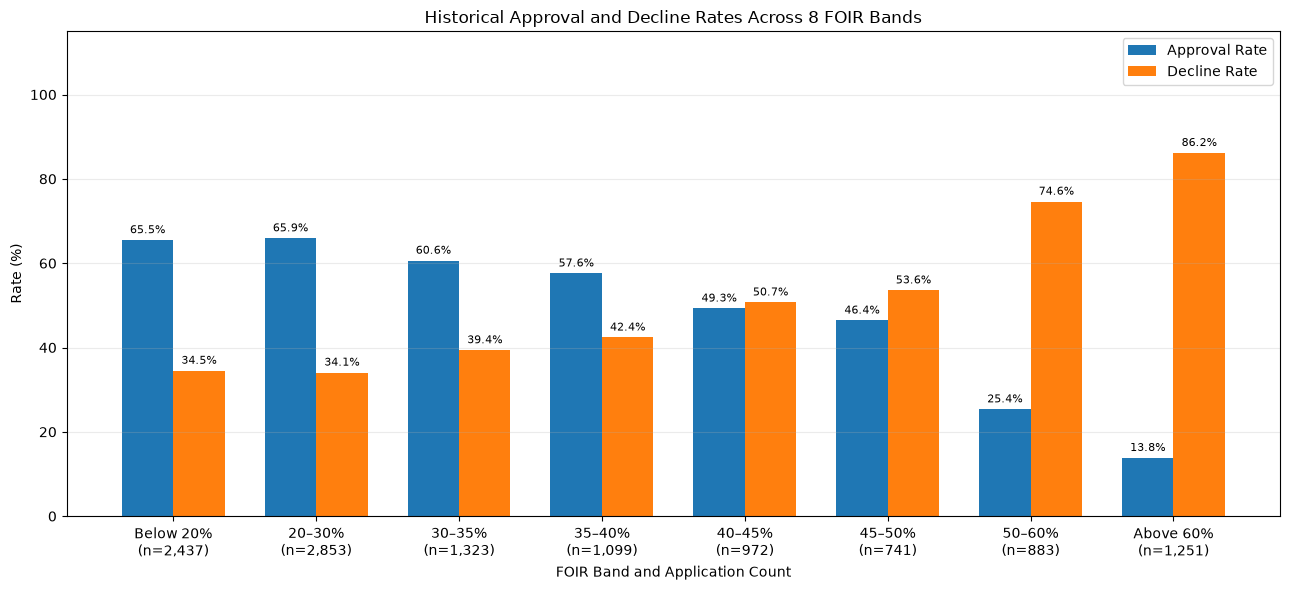

In [98]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define 8 FOIR bands
foir_bins = [
    -np.inf, 0.20, 0.30, 0.35, 0.40,
    0.45, 0.50, 0.60, np.inf
]

foir_labels = [
    "Below 20%",
    "20–30%",
    "30–35%",
    "35–40%",
    "40–45%",
    "45–50%",
    "50–60%",
    "Above 60%"
]

# Create a separate column for the detailed analysis
df_clean["foir_band_8"] = pd.cut(
    df_clean["foir"],
    bins=foir_bins,
    labels=foir_labels,
    right=False
)

# Calculate application counts and historical decisions
foir_summary_8 = (
    df_clean.dropna(subset=["foir_band_8"])
    .groupby("foir_band_8", observed=False)
    .agg(
        Total_Applications=("decision", "size"),
        Approved_Applications=(
            "decision",
            lambda x: (x == "Approved").sum()
        ),
        Declined_Applications=(
            "decision",
            lambda x: (x == "Declined").sum()
        )
    )
)

foir_summary_8["Approval_Rate_Pct"] = (
    foir_summary_8["Approved_Applications"]
    / foir_summary_8["Total_Applications"] * 100
)

foir_summary_8["Decline_Rate_Pct"] = (
    foir_summary_8["Declined_Applications"]
    / foir_summary_8["Total_Applications"] * 100
)

display(foir_summary_8.round(2))

# Plot approval and decline rates
x = np.arange(len(foir_summary_8))
width = 0.36

fig, ax = plt.subplots(figsize=(13, 6))

approval_bars = ax.bar(
    x - width / 2,
    foir_summary_8["Approval_Rate_Pct"],
    width,
    label="Approval Rate"
)

decline_bars = ax.bar(
    x + width / 2,
    foir_summary_8["Decline_Rate_Pct"],
    width,
    label="Decline Rate"
)

# Add percentage labels above bars
ax.bar_label(
    approval_bars,
    labels=[
        f"{v:.1f}%"
        for v in foir_summary_8["Approval_Rate_Pct"]
    ],
    padding=3,
    fontsize=8
)

ax.bar_label(
    decline_bars,
    labels=[
        f"{v:.1f}%"
        for v in foir_summary_8["Decline_Rate_Pct"]
    ],
    padding=3,
    fontsize=8
)

# Add application counts below the FOIR band labels
band_tick_labels = [
    f"{band}\n(n={count:,})"
    for band, count in zip(
        foir_summary_8.index.astype(str),
        foir_summary_8["Total_Applications"]
    )
]

ax.set_xticks(x)
ax.set_xticklabels(band_tick_labels)

ax.set_title("Historical Approval and Decline Rates Across 8 FOIR Bands")
ax.set_xlabel("FOIR Band and Application Count")
ax.set_ylabel("Rate (%)")
ax.set_ylim(0, 115)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Findings — Detailed FOIR Analysis Across Eight Bands

The eight-band analysis provides a more detailed view of the relationship between FOIR and historical loan decisions.

| FOIR band | Applications | Approval rate | Decline rate |
|---|---:|---:|---:|
| Below 20% | 2,437 | 65.5% | 34.5% |
| 20–30% | 2,853 | 65.9% | 34.1% |
| 30–35% | 1,323 | 60.6% | 39.4% |
| 35–40% | 1,099 | 57.6% | 42.4% |
| 40–45% | 972 | 49.3% | 50.7% |
| 45–50% | 741 | 46.4% | 53.6% |
| 50–60% | 883 | 25.4% | 74.6% |
| Above 60% | 1,251 | 13.8% | 86.2% |

Approval rates remain relatively stable at approximately 65–66% for applicants below 30% FOIR. They then decline gradually through the 30–40% bands. In the 40–45% band, the decline rate first exceeds 50%, reaching 50.7%.

The sharpest change occurs between the 45–50% and 50–60% bands: the decline rate increases from 53.6% to 74.6%, a rise of 21 percentage points. Above 60% FOIR, the decline rate reaches 86.2%, while the approval rate falls to just 13.8%.

Based on these historical patterns, I recommend **40% FOIR as a preliminary threshold for additional credit-risk review**, because approval rates fall below 50% in the 40–45% band. FOIR at or above 50% should be treated as a stronger warning indicator because historical declines increase substantially in this range. Neither threshold should automatically trigger rejection; applications should also be assessed using credit history, income stability, loan characteristics, and repayment capacity.

These findings describe historical lending decisions rather than proven future default risk. The proposed thresholds should be validated against actual repayment outcomes and the bank's affordability rules before implementation.

In [99]:
# Step 5.3.6: Final validation

print(
    "NTC count matches missing credit scores:",
    df_clean["is_ntc"].sum()
    == df_clean["credit_score"].isna().sum()
)

print(
    "NTC contains only 0 and 1:",
    set(df_clean["is_ntc"].unique()).issubset({0, 1})
)

print(
    "FOIR has no infinite values:",
    not np.isinf(df_clean["foir"].dropna()).any()
)

print(
    "Loan-to-income has no infinite values:",
    not np.isinf(df_clean["loan_to_income"].dropna()).any()
)

print(
    "FOIR band counts match valid FOIR records:",
    foir_analysis["Total_Applications"].sum()
    == df_clean["foir"].notna().sum()
)

print(
    "Missing FOIR count:",
    df_clean["foir"].isna().sum()
)

print(
    "NTC indicator matches missing credit scores:",
    (
        df_clean["is_ntc"]
        == df_clean["credit_score"].isna().astype(int)
    ).all()
)

NTC count matches missing credit scores: True
NTC contains only 0 and 1: True
FOIR has no infinite values: True
Loan-to-income has no infinite values: True
FOIR band counts match valid FOIR records: True
Missing FOIR count: 441
NTC indicator matches missing credit scores: True


### Step 5.3.6 — Final Validation of Engineered Features

**Objective:** Validate the NTC indicator, check for infinite financial ratios, and verify that FOIR-band counts account for all records with valid FOIR.

**Validation results:**

- The NTC count matches the number of missing credit scores: **True**.
- The NTC indicator contains only 0 and 1: **True**.
- FOIR contains no infinite values: **True**.
- Loan-to-income contains no infinite values: **True**.
- FOIR-band counts match the number of valid FOIR records: **True**.
- Missing FOIR count: **441**.

**Interpretation:**

All reported validation checks passed. The engineered features and FOIR categories are internally consistent with the dataset's missing-value patterns. The missing income values remain unresolved intentionally and will be handled during model preprocessing using training-set information only.

A separate row-level check should also confirm that every missing credit score corresponds to `is_ntc = 1` and every observed credit score corresponds to `is_ntc = 0`.

--------------------------------------------------------------------------------------------------------------

### FOIR Threshold and Credit Policy Recommendation

Historical approval rates decrease as FOIR increases. The approval rate falls from 65.73% for applicants below 30% FOIR to 59.25% for the 30–40% band and 48.04% for the 40–50% band. A sharper decline occurs at higher FOIR levels, with approval falling to 32.37% for the 50–55% band and just 14.18% above 55%.

Based on these historical patterns, I recommend **40% FOIR as a preliminary threshold for additional credit-risk review**. Applications above this level should receive closer assessment of income stability, existing obligations, credit history, and repayment capacity. FOIR above 50% can be treated as a higher-risk warning indicator. Neither threshold should automatically determine rejection, because other applicant characteristics and risk factors also matter.

This recommendation is based on historical approval behaviour and is not a validated credit policy. Before implementation, the bank should test these thresholds against actual repayment or default outcomes, affordability requirements, and its risk appetite. Historical approval decisions alone do not establish whether applicants will repay their loans.

--------------------------------------------------------------------------------------------------------------

### Step 5.3 — Overall Conclusion: Financial Obligations and Historical Approval

Feature engineering was completed to create `foir`, `loan_to_income`, and `is_ntc`. Of the 12,000 applications, 11,559 have valid FOIR values, while 441 contain missing FOIR because monthly income is unavailable. Historical approval rates decline consistently as FOIR increases, falling from **65.73%** below 30% to **14.18%** above 55%. This indicates a strong negative association between financial obligations relative to income and historical loan approval. Applicants with FOIR above 100% require particular attention because their combined EMI obligations exceed their recorded monthly income. The NTC indicator identifies 1,039 applicants without a recorded credit score, allowing them to be distinguished from applicants with observed scores. All reported feature-validation checks passed, and missing values will be handled during leakage-safe model preprocessing. These findings provide useful input for the next stage of model development but do not independently establish creditworthiness or future repayment outcomes.

---------------------------------------------------------------------------------------------------------------------------------

# Step 5.4 — Build the Logistic Regression Pre-Screener

The objective of this step is to build a baseline Logistic Regression model that predicts whether a loan application was historically declined or approved.

The target is encoded as `1 = Declined` and `0 = Approved`. The model uses the 12 features specified in the use case, while excluding application identifiers, application dates, city, gender, and the original decision column from the input features.

Missing values will be handled using training-data-derived imputers. Categorical features will be one-hot encoded, and numerical features will be scaled. The dataset will be split into 80% training data and 20% testing data using stratification and `random_state=42`.

The model will be evaluated using accuracy, precision and recall for the Declined class, a confusion matrix, and the five largest Logistic Regression coefficients. These results will help assess the model's usefulness for credit pre-screening while highlighting the risks of wrongly declining historically approved applicants.

In [100]:
import pandas as pd
import numpy as np

# Target: 1 = Declined, 0 = Approved
y = df_clean["decision"].map({
    "Approved": 0,
    "Declined": 1
})

# The 12 features required by the use case
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

feature_columns = numeric_features + categorical_features

X = df_clean[feature_columns].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget counts:")
print(y.value_counts().sort_index())
print("\nMissing target values:", y.isna().sum())
print("\nMissing values in selected features:")
print(X.isnull().sum()[X.isnull().sum() > 0])

print("\nExcluded columns present in X:")
excluded_columns = [
    "application_id",
    "application_date",
    "city",
    "gender",
    "decision"
]
print([col for col in excluded_columns if col in X.columns])

Feature matrix shape: (12000, 12)
Target shape: (12000,)

Target counts:
decision
0    6353
1    5647
Name: count, dtype: int64

Missing target values: 0

Missing values in selected features:
credit_score      1039
foir               441
loan_to_income     441
dtype: int64

Excluded columns present in X:
[]


### Target and Feature Selection — Interpretation

The target represents the historical loan decision: `0` means Approved and `1` means Declined. The model receives 12 specified applicant and loan-related features, including credit history, affordability measures, employment information, and loan purpose.

The identifier, application date, city, gender, and original decision are excluded from the feature matrix. The target is kept separately from the inputs so the model learns to predict the historical decision rather than using the answer as an input.

Missing feature values are not removed at this stage. They will be imputed during preprocessing after the train-test split to prevent information from the test set influencing the training process.

In [101]:
expected_features = {
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier",
    "employment_type",
    "loan_purpose"
}

excluded_columns = {
    "application_id",
    "application_date",
    "city",
    "gender",
    "decision"
}

validation_results = {
    "Dataset has 12,000 rows": len(df_clean) == 12000,
    "Feature matrix has 12 columns": X.shape[1] == 12,
    "All required features are selected": set(X.columns) == expected_features,
    "No prohibited columns are features": not bool(set(X.columns) & excluded_columns),
    "No missing target values": y.isna().sum() == 0,
    "Target contains only 0 and 1": set(y.unique()) == {0, 1}
}

validation_table = pd.DataFrame(
    list(validation_results.items()),
    columns=["Validation", "Passed"]
)

display(validation_table)
print(
    f"\nValidation result: "
    f"{validation_table['Passed'].sum()}/{len(validation_table)} checks passed."
)

if not validation_table["Passed"].all():
    raise ValueError("Please resolve failed target or feature validation checks.")

,Validation,Passed
0,"Dataset has 12,000 rows",True
1,Feature matrix has 12 columns,True
2,All required features are selected,True
3,No prohibited columns are features,True
4,No missing target values,True
5,Target contains only 0 and 1,True



Validation result: 6/6 checks passed.


In [102]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

Training feature shape: (9600, 12)
Testing feature shape: (2400, 12)
Training target shape: (9600,)
Testing target shape: (2400,)

Training target proportions:
decision
0    0.5294
1    0.4706
Name: proportion, dtype: float64

Testing target proportions:
decision
0    0.5296
1    0.4704
Name: proportion, dtype: float64


### Train-Test Split — Interpretation

The dataset is divided into training and testing subsets using an 80/20 split, `stratify=y`, and `random_state=42`. Stratification preserves approximately the same proportion of Approved and Declined applications in both subsets, while the fixed random state makes the split reproducible.

The training subset is used to fit the preprocessing steps and Logistic Regression model. The held-out test subset is reserved for evaluating performance on applications not used to fit the model.

In [103]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Retrieve the original rows for training and testing
train_data = df_clean.loc[X_train.index].copy()
test_data = df_clean.loc[X_test.index].copy()

# 2. Calculate employment-type income medians using training data only
income_medians = train_data.groupby("employment_type")[
    "monthly_income"
].median()

overall_income_median = train_data["monthly_income"].median()

# 3. Impute missing income using employment-type medians
# Fall back to the training-set overall median if needed
for data in [train_data, test_data]:
    data["monthly_income"] = data["monthly_income"].fillna(
        data["employment_type"].map(income_medians)
    )
    data["monthly_income"] = data["monthly_income"].fillna(
        overall_income_median
    )

# 4. Recalculate financial ratios from the imputed income
for data in [train_data, test_data]:
    data["foir"] = (
        (data["existing_emi"] + data["proposed_emi"])
        / data["monthly_income"]
    )

    data["loan_to_income"] = (
        data["loan_amount"]
        / (data["monthly_income"] * 12)
    )

# 5. Update the existing feature matrices with recalculated ratios
X_train = X_train.copy()
X_test = X_test.copy()

X_train["foir"] = train_data["foir"]
X_train["loan_to_income"] = train_data["loan_to_income"]

X_test["foir"] = test_data["foir"]
X_test["loan_to_income"] = test_data["loan_to_income"]

# 6. Define numeric preprocessing: median imputation and scaling
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 7. Define categorical preprocessing: mode imputation and encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 8. Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# 9. Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 10. Validate the processed datasets
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Training rows preserved:", X_train_processed.shape[0] == len(y_train))
print("Testing rows preserved:", X_test_processed.shape[0] == len(y_test))
print("Training income missing:", train_data["monthly_income"].isna().sum())
print("Testing income missing:", test_data["monthly_income"].isna().sum())
print("Training FOIR missing:", X_train["foir"].isna().sum())
print("Testing FOIR missing:", X_test["foir"].isna().sum())
print("Training LTI missing:", X_train["loan_to_income"].isna().sum())
print("Testing LTI missing:", X_test["loan_to_income"].isna().sum())
print("Transformed feature count:", len(preprocessor.get_feature_names_out()))


Processed training shape: (9600, 21)
Processed testing shape: (2400, 21)
Training rows preserved: True
Testing rows preserved: True
Training income missing: 0
Testing income missing: 0
Training FOIR missing: 0
Testing FOIR missing: 0
Training LTI missing: 0
Testing LTI missing: 0
Transformed feature count: 21


### Preprocessing Validation — Results and Interpretation

The preprocessing pipeline executed successfully and preserved all training and testing observations.

- **Training dataset:** 9,600 rows and 21 transformed features.
- **Testing dataset:** 2,400 rows and 21 transformed features.
- **Missing income values:** Zero in both training and testing datasets after imputation.
- **Missing FOIR and loan-to-income values:** Zero in both datasets after recalculation and preprocessing.
- **Row preservation:** Both training and testing row counts were preserved.
- **Feature consistency:** The preprocessing pipeline produced 21 transformed features.

These results confirm that the preprocessing pipeline successfully handled missing values, recalculated the financial ratios, encoded categorical features, and scaled numerical features. The fitted pipeline was applied consistently to the training and testing datasets.

In [104]:
from scipy import sparse

def has_only_finite_values(matrix):
    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)
    return bool(np.isfinite(values).all())

transformed_checks = {
    "Training transformed data has no non-finite values":
        has_only_finite_values(X_train_processed),
    "Testing transformed data has no non-finite values":
        has_only_finite_values(X_test_processed),
    "Training transformed rows preserved":
        X_train_processed.shape[0] == len(y_train),
    "Testing transformed rows preserved":
        X_test_processed.shape[0] == len(y_test),
    "Training and testing have the same feature count":
        X_train_processed.shape[1] == X_test_processed.shape[1]
}

transformed_validation = pd.DataFrame(
    list(transformed_checks.items()),
    columns=["Validation", "Passed"]
)

display(transformed_validation)
print(
    f"\nTransformed-data validation: "
    f"{transformed_validation['Passed'].sum()}/{len(transformed_validation)} checks passed."
)

if not transformed_validation["Passed"].all():
    raise ValueError("Review preprocessing before training the model.")

,Validation,Passed
0,Training transformed data has no non-finite va...,True
1,Testing transformed data has no non-finite values,True
2,Training transformed rows preserved,True
3,Testing transformed rows preserved,True
4,Training and testing have the same feature count,True



Transformed-data validation: 5/5 checks passed.


### Preprocessing — Interpretation

The preprocessing pipeline handles missing values and prepares the selected features for Logistic Regression.

- **Missing monthly income:** Missing income values were imputed using the median income for the applicant's employment type, calculated from the training data. The overall training-set median was used as a fallback when an employment-type median was unavailable.
- **Financial feature recalculation:** After income imputation, `foir` and `loan_to_income` were recalculated using the original EMI, loan amount, and imputed income values.
- **Numerical features:** Missing numerical values, including missing credit scores, were handled using training-set medians, followed by standardization.
- **Categorical features:** Missing categorical values were filled using the most frequent training-set category, followed by one-hot encoding.

The preprocessing pipeline was fitted on the training data and then applied to the test data. The validation checks confirmed that all 9,600 training rows and 2,400 testing rows were preserved, the recalculated financial features contained no missing values, and the transformed datasets contained only finite values.

The pipeline produced **21 transformed features** from the original 12 selected features. The original `df_clean` dataset was not modified by the income-imputation procedure.

In [105]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(max_iter=1000)

baseline_model.fit(X_train_processed, y_train)

y_pred = baseline_model.predict(X_test_processed)

print("Logistic Regression training completed successfully.")
print("Number of test predictions:", len(y_pred))
print("Number of test applications:", len(y_test))

Logistic Regression training completed successfully.
Number of test predictions: 2400
Number of test applications: 2400


In [106]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

declined_precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

declined_recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print(f"Accuracy: {accuracy:.4f} ({accuracy:.2%})")
print(f"Precision for Declined: {declined_precision:.4f}")
print(f"Recall for Declined: {declined_recall:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Approved", "Declined"],
        zero_division=0
    )
)

Accuracy: 0.7904 (79.04%)
Precision for Declined: 0.7909
Recall for Declined: 0.7538

Classification report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



### Logistic Regression — Model Evaluation and Interpretation

The Logistic Regression model trained successfully and generated predictions for all **2,400 test applications**.

The model achieved the following evaluation results:

| Metric | Score |
|---|---:|
| Accuracy | 79.04% |
| Precision for Declined | 79.09% |
| Recall for Declined | 75.38% |
| F1-score for Approved | 0.81 |
| F1-score for Declined | 0.77 |

**Interpretation:**

- **Accuracy (79.04%):** The model correctly classified approximately 79% of the test applications.
- **Precision for Declined (79.09%):** Of the applications predicted as Declined, approximately 79% were historically declined.
- **Recall for Declined (75.38%):** The model correctly identified approximately 75% of all historically declined applications.
- **Approved applications:** The model achieved 79% precision and 82% recall for the Approved class, with an F1-score of 0.81.
- **Declined applications:** The model achieved an F1-score of 0.77, indicating a balance between precision and recall for the Declined class.

The macro-average F1-score was 0.79, and the weighted-average F1-score was also 0.79.

Overall, the baseline model demonstrates useful predictive performance for distinguishing between historical approval and decline decisions. However, the model's performance must also be assessed in terms of false declines, missed historical declines, and the business risk limits specified in the use case.

These metrics measure agreement with historical decisions, not actual loan repayment or default risk. The model should therefore support analyst review rather than independently determine loan approvals or rejections.

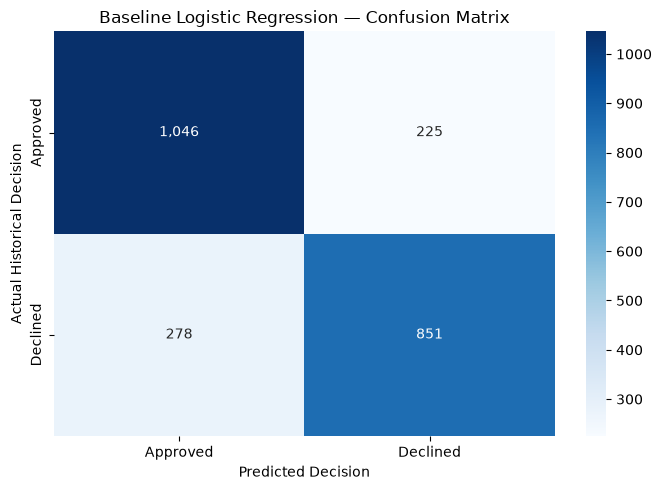

True Negatives (Approved correctly predicted): 1046
False Positives (Approved incorrectly predicted Declined): 225
False Negatives (Declined incorrectly predicted Approved): 278
True Positives (Declined correctly predicted): 851

Total applications represented: 2400
Test applications: 2400


In [107]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=["Approved", "Declined"],
    yticklabels=["Approved", "Declined"]
)

plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Decision")
plt.ylabel("Actual Historical Decision")
plt.tight_layout()
plt.show()

print("True Negatives (Approved correctly predicted):", tn)
print("False Positives (Approved incorrectly predicted Declined):", fp)
print("False Negatives (Declined incorrectly predicted Approved):", fn)
print("True Positives (Declined correctly predicted):", tp)

print("\nTotal applications represented:", cm.sum())
print("Test applications:", len(y_test))

### Business Interpretation — Confusion Matrix

The Logistic Regression model was evaluated on **2,400 test applications**. It correctly classified 1,046 historically approved applications and 851 historically declined applications.

The model made two types of errors:

- **225 false declines:** Applications historically approved by the credit team were predicted as Declined. These represent approximately **17.7% of the 1,271 historically approved test applications**.
- **278 missed historical declines:** Applications historically declined by the credit team were predicted as Approved.

The model correctly classified 1,897 out of 2,400 applications, consistent with its **79.04% accuracy**. However, accuracy alone does not indicate whether the model is suitable for credit pre-screening.

False declines are particularly important because they could cause potentially eligible applicants to be unnecessarily rejected. Missed historical declines are also important because applications that previously failed the credit team's decision process may not receive the additional scrutiny they need.

Historical approval and decline decisions are proxies for the model's target, not proof of actual repayment performance or future default risk. Therefore, the model should support credit analysts rather than independently determine loan outcomes.

In Step 5.5, probability thresholds should be evaluated to identify whether auto-declining applications can reduce manual-review workload while keeping historically approved applications within the assignment's **5% risk limit**.

In [108]:
# Get the feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get the fitted Logistic Regression coefficients
coefficients = baseline_model.coef_[0]

# Confirm that feature names and coefficients align
assert len(feature_names) == len(coefficients), (
    "Feature-name count does not match coefficient count."
)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

top_five_coefficients = (
    coefficient_table
    .sort_values("Absolute_Coefficient", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

display(top_five_coefficients)

,Feature,Coefficient,Absolute_Coefficient
0,numeric__foir,1.219897,1.219897
1,numeric__credit_score,-1.009155,1.009155
2,numeric__delinquencies_24m,0.980179,0.980179
3,categorical__employment_type_Gig / Contract,0.617342,0.617342
4,categorical__employment_type_Salaried,-0.444675,0.444675


### Business Interpretation — Top Five Logistic Regression Coefficients

The five features with the largest absolute Logistic Regression coefficients are FOIR, credit score, recent delinquencies, Gig / Contract employment, and Salaried employment.

Because the target is encoded as `1 = Declined` and `0 = Approved`, positive coefficients push the model towards predicting Declined, while negative coefficients push it away from predicting Declined, holding other features constant.

- **FOIR (+1.2199):** Higher FOIR is associated with higher predicted decline odds. This aligns with the earlier analysis, which showed lower historical approval rates as FOIR increased.
- **Credit score (−1.0092):** Higher credit scores are associated with lower predicted decline odds, holding other features constant.
- **Delinquencies in the last 24 months (+0.9802):** More recent delinquencies are associated with higher predicted decline odds.
- **Gig / Contract employment (+0.6173):** This category is associated with higher predicted decline log-odds relative to the encoder's reference employment category.
- **Salaried employment (−0.4447):** This category is associated with lower predicted decline log-odds relative to the same reference category.

The numerical features were standardized before model training, so their coefficients correspond to changes in the standardized features. Employment-category coefficients are relative to the encoder's reference category. Coefficient values are changes in log-odds, not direct percentage-point changes in decline probability.

These coefficients describe associations learned from historical decisions; they do not establish causation or prove future repayment outcomes. The results can help analysts understand model behaviour, but predictions should be combined with affordability checks, appropriate human oversight, and fairness monitoring.

In [109]:
final_checks = {
    "Training set contains 9,600 applications":
        len(X_train) == 9600,
    "Test set contains 2,400 applications":
        len(X_test) == 2400,
    "Test predictions match test-set size":
        len(y_pred) == len(y_test),
    "Confusion matrix accounts for all test applications":
        cm.sum() == len(y_test),
    "Five coefficients extracted":
        len(top_five_coefficients) == 5,
    "No prohibited columns used as features":
        not bool(set(X.columns) & {
            "application_id", "application_date",
            "city", "gender", "decision"
        }),
    "Training transformed data has no non-finite values":
        has_only_finite_values(X_train_processed),
    "Testing transformed data has no non-finite values":
        has_only_finite_values(X_test_processed)
}

final_validation = pd.DataFrame(
    list(final_checks.items()),
    columns=["Validation", "Passed"]
)

display(final_validation)

passed = int(final_validation["Passed"].sum())
total = len(final_validation)

print(f"\nFinal validation result: {passed}/{total} checks passed.")

if passed != total:
    print("Review the failed checks before marking Step 5.4 complete.")
else:
    print("All Step 5.4 validation checks passed.")

,Validation,Passed
0,"Training set contains 9,600 applications",True
1,"Test set contains 2,400 applications",True
2,Test predictions match test-set size,True
3,Confusion matrix accounts for all test applica...,True
4,Five coefficients extracted,True
5,No prohibited columns used as features,True
6,Training transformed data has no non-finite va...,True
7,Testing transformed data has no non-finite values,True



Final validation result: 8/8 checks passed.
All Step 5.4 validation checks passed.


### Step 5.4 — Overall Conclusion: Logistic Regression Pre-Screener

A baseline Logistic Regression model was developed to predict historical loan decisions using the 12 features specified in the use case. The target was encoded as `1 = Declined` and `0 = Approved`. The dataset was split into 9,600 training applications and 2,400 test applications using stratification and `random_state=42`.

Missing monthly income was imputed using employment-type medians calculated from the training set, with the overall training-set median as a fallback. FOIR and loan-to-income ratios were recalculated after income imputation. Remaining numerical missing values were handled using training-set medians, categorical values using the most frequent training-set category, numerical features were standardized, and categorical features were one-hot encoded. Preprocessing was fitted on training data only.

The model achieved **79.04% accuracy**, **79.09% precision for Declined**, and **75.38% recall for Declined**. The confusion matrix showed 225 historically approved applications incorrectly predicted as Declined, representing approximately 17.7% of the 1,271 historically approved test applications. Another 278 historically declined applications were incorrectly predicted as Approved.

The five largest absolute coefficients were associated with FOIR, credit score, recent delinquencies, Gig / Contract employment, and Salaried employment. Higher FOIR and more recent delinquencies were associated with higher predicted decline odds, while higher credit scores were associated with lower predicted decline odds.

All **8/8 final validation checks passed**. The model provides an interpretable baseline for credit pre-screening, but it should not be used as a standalone automatic rejection system. Step 5.5 will evaluate probability thresholds against the requirement that no more than 5% of auto-declined applications were historically approved, while seeking to reduce manual-review workload.

-------------------------------------------------------------------------------------------------------------------------------

# 5.5  Set the auto-decline threshold

,Threshold,Auto-Declined Count,Auto-Declined (%),Historically Approved Among Auto-Declined,Wrongly Declined (%),Meets 5% Risk Limit
0,0.50,1076,44.83,225,20.91,False
1,0.60,905,37.71,152,16.80,False
2,0.70,738,30.75,89,12.06,False
3,0.80,562,23.42,39,6.94,False
4,0.85,473,19.71,28,5.92,False
5,0.90,363,15.12,17,4.68,True
6,0.95,239,9.96,5,2.09,True


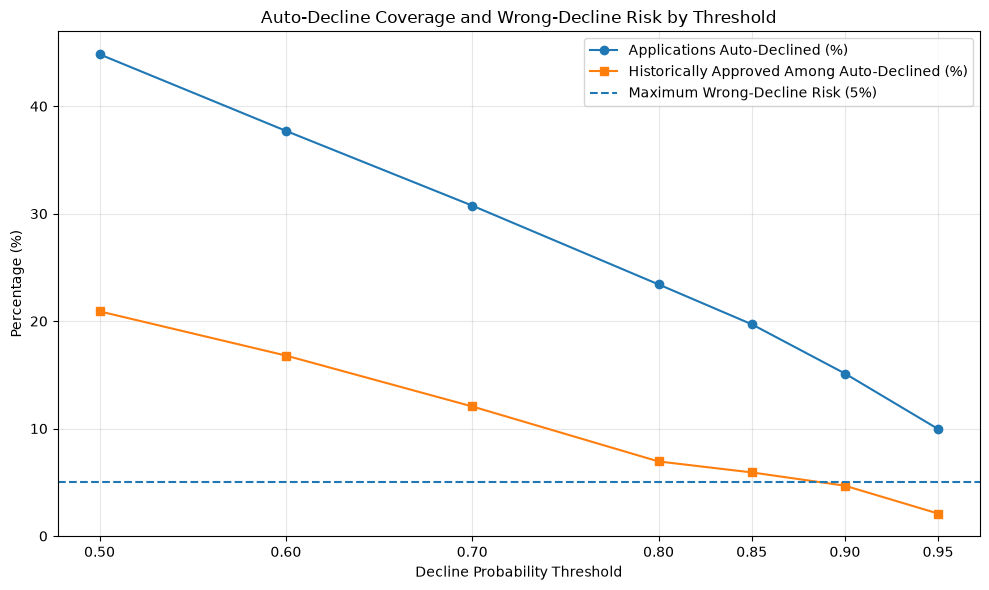


--- Recommended Auto-Decline Threshold ---
Selected threshold: 0.90
Test applications auto-declined: 363
Auto-decline rate: 15.12%
Wrong-decline risk: 4.68%
Estimated monthly applications auto-declined: 453.8
Estimated analyst hours freed per month: 189.1


In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get the predicted probability of Declined (class 1)
declined_class_index = list(baseline_model.classes_).index(1)

decline_probabilities = baseline_model.predict_proba(
    X_test_processed
)[:, declined_class_index]

# Actual historical decisions: 0 = Approved, 1 = Declined
y_test_array = np.asarray(y_test)

# 2. Define the required thresholds
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:

    # Auto-decline only when decline probability meets the threshold
    auto_decline_mask = decline_probabilities >= threshold

    total_auto_declined = int(auto_decline_mask.sum())

    # Percentage of all test applications auto-declined
    auto_decline_pct = (
        total_auto_declined / len(y_test_array)
    ) * 100

    # Of auto-declined applications, count historical approvals
    wrongly_declined = int(
        ((y_test_array == 0) & auto_decline_mask).sum()
    )

    # Risk: percentage of auto-declined applications
    # that were historically Approved
    wrong_decline_pct = (
        wrongly_declined / total_auto_declined * 100
        if total_auto_declined > 0
        else 0.0
    )

    results.append({
        "Threshold": threshold,
        "Auto-Declined Count": total_auto_declined,
        "Auto-Declined (%)": auto_decline_pct,
        "Historically Approved Among Auto-Declined": wrongly_declined,
        "Wrongly Declined (%)": wrong_decline_pct
    })

threshold_results = pd.DataFrame(results)

# 3. Identify thresholds that satisfy the 5% risk limit
threshold_results["Meets 5% Risk Limit"] = (
    (threshold_results["Wrongly Declined (%)"] <= 5)
    & (threshold_results["Auto-Declined Count"] > 0)
)

# Display the threshold comparison table
display(
    threshold_results.round({
        "Threshold": 2,
        "Auto-Declined (%)": 2,
        "Wrongly Declined (%)": 2
    })
)

# 4. Plot both required lines on one chart
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Auto-Declined (%)"],
    marker="o",
    label="Applications Auto-Declined (%)"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Wrongly Declined (%)"],
    marker="s",
    label="Historically Approved Among Auto-Declined (%)"
)

plt.axhline(
    y=5,
    linestyle="--",
    label="Maximum Wrong-Decline Risk (5%)"
)

plt.xticks(thresholds)
plt.xlabel("Decline Probability Threshold")
plt.ylabel("Percentage (%)")
plt.title("Auto-Decline Coverage and Wrong-Decline Risk by Threshold")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 5. Select the valid threshold with the greatest auto-decline volume
valid_thresholds = threshold_results[
    threshold_results["Meets 5% Risk Limit"]
]

if valid_thresholds.empty:
    print("No tested threshold satisfies the 5% risk limit.")
    print("A higher threshold or further model review is required.")
else:
    selected_row = valid_thresholds.loc[
        valid_thresholds["Auto-Declined Count"].idxmax()
    ]

    selected_threshold = float(selected_row["Threshold"])
    selected_rate = float(selected_row["Auto-Declined (%)"])
    selected_count = int(selected_row["Auto-Declined Count"])
    selected_wrong_rate = float(selected_row["Wrongly Declined (%)"])

    # 6. Translate test-set results into the monthly business case
    monthly_applications = 3000
    review_minutes = 25

    monthly_auto_declines = (
        selected_rate / 100
    ) * monthly_applications

    monthly_hours_freed = (
        monthly_auto_declines * review_minutes / 60
    )

    print("\n--- Recommended Auto-Decline Threshold ---")
    print(f"Selected threshold: {selected_threshold:.2f}")
    print(f"Test applications auto-declined: {selected_count}")
    print(f"Auto-decline rate: {selected_rate:.2f}%")
    print(f"Wrong-decline risk: {selected_wrong_rate:.2f}%")
    print(f"Estimated monthly applications auto-declined: {monthly_auto_declines:.1f}")
    print(f"Estimated analyst hours freed per month: {monthly_hours_freed:.1f}")



### Monthly Business Impact at the Selected Threshold

The selected auto-decline threshold is **0.90**, which auto-declines 15.12% of test applications while keeping the proportion of historically approved applications among auto-declined cases at 4.68%, within the bank's 5% risk limit.

Based on **3,000 applications per month**:

- **Applications auto-declined:** 3,000 × 15.12% = approximately **454 applications per month**.
- **Manual review time saved:** 454 × 25 minutes = 11,350 minutes per month.
- **Analyst hours freed:** 11,350 ÷ 60 = approximately **189 hours per month**.

Therefore, the proposed threshold could free approximately **189 analyst hours per month**, assuming every auto-declined application would otherwise require a full 25-minute manual review. These figures are estimates based on the test-set auto-decline rate and should be validated against future application volumes and outcomes.

### Step 5.5 — Auto-Decline Threshold Analysis and Business Impact

The Logistic Regression model was evaluated at seven decline-probability thresholds, ranging from 0.50 to 0.95. As the threshold increased, the percentage of applications selected for auto-decline decreased, and the proportion of historically approved applications among those auto-declined also declined.

The bank requires that no more than **5% of auto-declined applications** may have been historically approved. The thresholds of 0.90 and 0.95 satisfied this requirement, with wrong-decline risks of 4.68% and 2.09%, respectively. The **recommended threshold is 0.90**, because it satisfies the risk limit while auto-declining the greater number of applications among the qualifying thresholds.

At this threshold, **363 out of 2,400 test applications (15.12%)** would be auto-declined. Of these, 17 were historically approved, resulting in a wrong-decline risk of **4.68%**.

Using the bank's monthly volume of 3,000 applications, the estimated monthly impact is:

- **Applications auto-declined:** Approximately 454 per month.
- **Analyst time saved:** Approximately 189 hours per month, assuming each application would otherwise require a 25-minute manual review.

The 0.95 threshold would reduce wrong-decline risk further to 2.09%, but would auto-decline only 9.96% of test applications. Therefore, the 0.90 threshold provides a better balance between risk control and operational efficiency among the tested options.

These estimates assume that every auto-declined application would otherwise receive a full manual review. The model predicts historical credit-team decisions rather than actual loan repayment or default outcomes. Before deployment, the bank should validate the threshold on additional data, monitor false declines and fairness across applicant groups, and maintain appropriate human oversight. The threshold should support the credit-review process rather than serve as an unreviewed final lending decision.

# 5.6  Fairness check

Historical approval rate by gender:


,gender,Applications,Approved_Count,Approval_Rate_Pct
0,Female,3795,1914,50.43
1,Male,8205,4439,54.10



Historical approval rate by employment type and gender:


,employment_type,gender,Applications,Approved_Count,Approval_Rate_Pct
0,Business Owner,Female,370,191,51.62
1,Business Owner,Male,1379,704,51.05
2,Gig / Contract,Female,811,281,34.65
3,Gig / Contract,Male,955,336,35.18
4,Salaried,Female,2150,1221,56.79
5,Salaried,Male,4907,2898,59.06
6,Self-Employed Professional,Female,464,221,47.63
7,Self-Employed Professional,Male,964,501,51.97


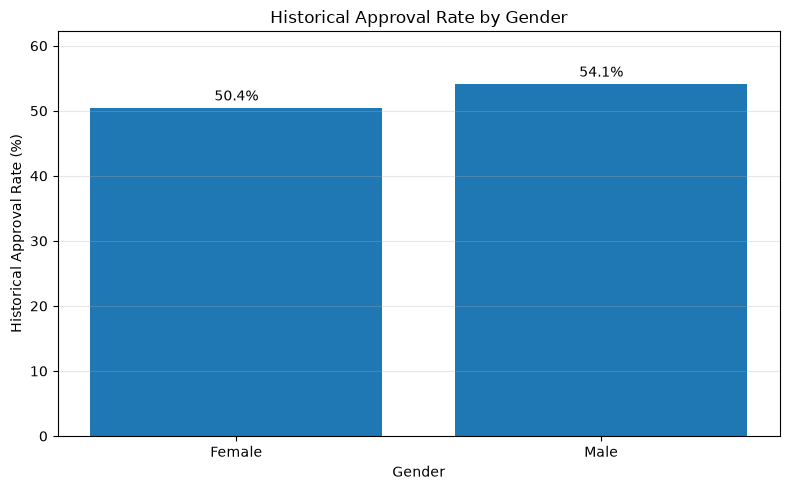

In [111]:
# Step 5.6.1 — Historical approval rate by gender

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the cleaned dataset for fairness analysis
fairness_data = df_clean.copy()

# Calculate historical approval rates by gender
approval_by_gender = (
    fairness_data.assign(
        approved=(fairness_data["decision"] == "Approved").astype(int)
    )
    .groupby("gender", dropna=False)
    .agg(
        Applications=("decision", "size"),
        Approved_Count=("approved", "sum"),
        Approval_Rate=("approved", "mean")
    )
    .reset_index()
)

approval_by_gender["Approval_Rate_Pct"] = (
    approval_by_gender["Approval_Rate"] * 100
)

print("Historical approval rate by gender:")
display(
    approval_by_gender[
        ["gender", "Applications", "Approved_Count", "Approval_Rate_Pct"]
    ].round(2)
)

# Historical approval rates within each employment type
approval_by_gender_employment = (
    fairness_data.assign(
        approved=(fairness_data["decision"] == "Approved").astype(int)
    )
    .groupby(["employment_type", "gender"], dropna=False)
    .agg(
        Applications=("decision", "size"),
        Approved_Count=("approved", "sum"),
        Approval_Rate=("approved", "mean")
    )
    .reset_index()
)

approval_by_gender_employment["Approval_Rate_Pct"] = (
    approval_by_gender_employment["Approval_Rate"] * 100
)

print("\nHistorical approval rate by employment type and gender:")
display(
    approval_by_gender_employment[
        [
            "employment_type",
            "gender",
            "Applications",
            "Approved_Count",
            "Approval_Rate_Pct"
        ]
    ].round(2)
)

# Plot historical approval rate by gender
gender_plot = approval_by_gender.sort_values("gender").copy()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    gender_plot["gender"].astype(str),
    gender_plot["Approval_Rate_Pct"]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.xlabel("Gender")
plt.ylabel("Historical Approval Rate (%)")
plt.title("Historical Approval Rate by Gender")
plt.ylim(
    0,
    max(gender_plot["Approval_Rate_Pct"].max() * 1.15, 1)
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Step 5.6.1 — Historical Approval Rate by Gender: Findings and Interpretation

The historical approval rate was **50.43% for Female applicants** and **54.10% for Male applicants**, a difference of **3.67 percentage points** in favour of Male applicants.

Examining approval rates within employment types provides additional context:

| Employment Type | Female Approval Rate | Male Approval Rate |
|---|---:|---:|
| Business Owner | 51.62% | 51.05% |
| Gig / Contract | 34.65% | 35.18% |
| Salaried | 56.79% | 59.06% |
| Self-Employed Professional | 47.63% | 51.97% |

The differences are not uniform across employment types. Female applicants had a slightly higher historical approval rate among Business Owners, while Male applicants had higher rates in the other three employment categories. This suggests that employment type and other applicant characteristics may contribute to the overall gender gap, but these descriptive results alone cannot establish its cause.

Median monthly income by gender:


,gender,Applications,Median_Monthly_Income
0,Female,3795,44000.0
1,Male,8205,54000.0



Gig / Contract representation by gender:


,gender,Gig_Contract_Count,Total_Applicants,Gig_Contract_Share_Pct
0,Female,811,3795,21.37
1,Male,955,8205,11.64


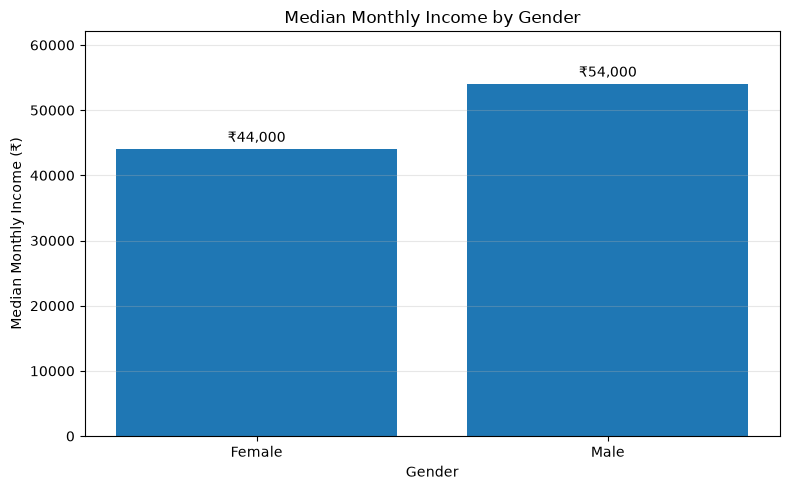

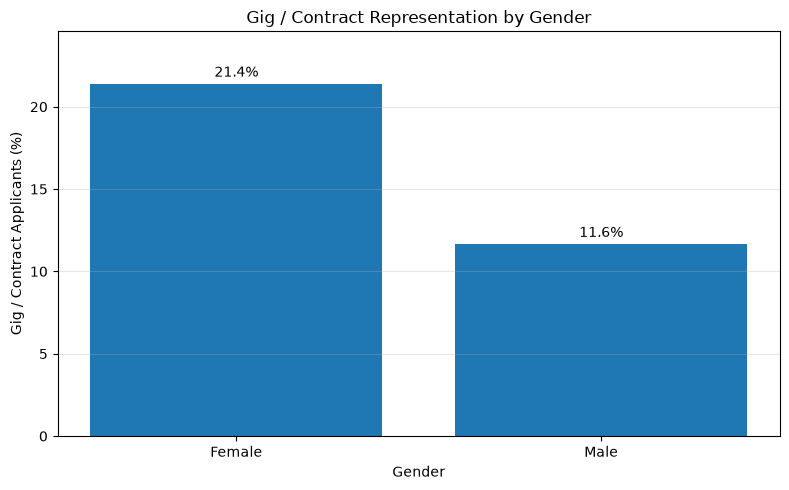

In [112]:
# Step 5.6.2 — Income and employment composition by gender

# Median monthly income by gender
median_income_by_gender = (
    fairness_data.groupby("gender", dropna=False)
    .agg(
        Applications=("monthly_income", "size"),
        Median_Monthly_Income=("monthly_income", "median")
    )
    .reset_index()
)

print("Median monthly income by gender:")
display(median_income_by_gender.round(2))

# Gig / Contract representation within each gender group
gig_share_by_gender = (
    fairness_data.assign(
        is_gig_contract=(
            fairness_data["employment_type"] == "Gig / Contract"
        ).astype(int)
    )
    .groupby("gender", dropna=False)
    .agg(
        Gig_Contract_Count=("is_gig_contract", "sum"),
        Total_Applicants=("is_gig_contract", "size"),
        Gig_Contract_Share=("is_gig_contract", "mean")
    )
    .reset_index()
)

gig_share_by_gender["Gig_Contract_Share_Pct"] = (
    gig_share_by_gender["Gig_Contract_Share"] * 100
)

print("\nGig / Contract representation by gender:")
display(
    gig_share_by_gender[
        [
            "gender",
            "Gig_Contract_Count",
            "Total_Applicants",
            "Gig_Contract_Share_Pct"
        ]
    ].round(2)
)

# Plot median monthly income by gender
income_plot = median_income_by_gender.sort_values("gender").copy()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    income_plot["gender"].astype(str),
    income_plot["Median_Monthly_Income"]
)

plt.bar_label(
    bars,
    labels=[
        f"₹{value:,.0f}"
        for value in income_plot["Median_Monthly_Income"]
    ],
    padding=3
)

plt.xlabel("Gender")
plt.ylabel("Median Monthly Income (₹)")
plt.title("Median Monthly Income by Gender")
plt.ylim(
    0,
    max(income_plot["Median_Monthly_Income"].max() * 1.15, 1)
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot Gig / Contract share by gender
gig_plot = gig_share_by_gender.sort_values("gender").copy()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    gig_plot["gender"].astype(str),
    gig_plot["Gig_Contract_Share_Pct"]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.xlabel("Gender")
plt.ylabel("Gig / Contract Applicants (%)")
plt.title("Gig / Contract Representation by Gender")
plt.ylim(
    0,
    max(gig_plot["Gig_Contract_Share_Pct"].max() * 1.15, 1)
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Step 5.6.2 — Income and Employment Composition by Gender: Findings and Interpretation

The median monthly income was **₹44,000 for Female applicants** and **₹54,000 for Male applicants**, a difference of ₹10,000. Gig / Contract workers represented **21.37% of Female applicants**, compared with **11.64% of Male applicants**.

These results show differences in the income distribution and employment composition of the two groups. Because income and employment type may be associated with historical credit decisions, these differences could contribute to the observed approval-rate gap. However, the analysis does not establish that these characteristics fully explain the gap or that the historical decisions were free from bias.

Model auto-decline rate by gender (threshold = 0.90):


,gender,Test_Applications,Auto_Declined_Count,Auto_Decline_Rate_Pct
0,Female,750,117,15.60
1,Male,1650,246,14.91


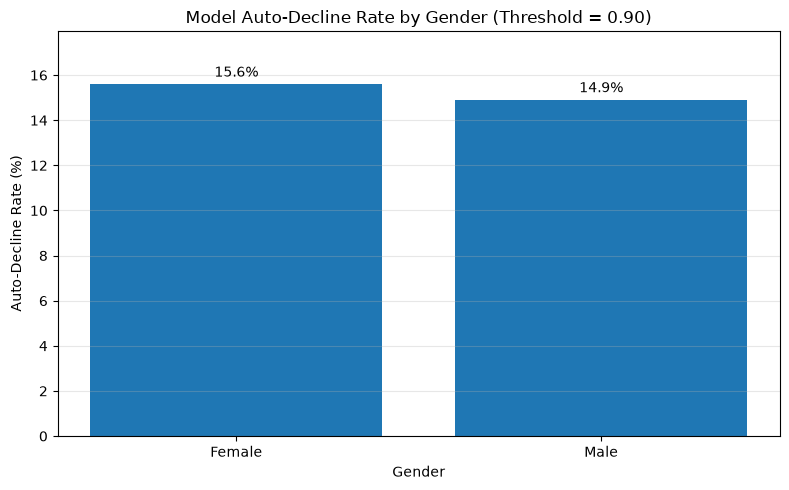

In [113]:
# Step 5.6.3 — Model Auto-Decline Rate by Gender 

# Use the same test rows and fitted model from Step 5.4
selected_threshold = 0.90

test_fairness = df_clean.loc[
    X_test.index, ["gender", "decision"]
].copy()

# Obtain the probability of Declined (class 1)
declined_class_index = list(baseline_model.classes_).index(1)

decline_probabilities = baseline_model.predict_proba(
    X_test_processed
)[:, declined_class_index]

# Confirm probability and row alignment
assert len(decline_probabilities) == len(test_fairness), (
    "Prediction count does not match the test dataset."
)

test_fairness["decline_probability"] = decline_probabilities

# Apply the selected threshold
test_fairness["auto_declined"] = (
    test_fairness["decline_probability"] >= selected_threshold
).astype(int)

# Calculate auto-decline rates within each gender group
auto_decline_by_gender = (
    test_fairness.groupby("gender", dropna=False)
    .agg(
        Test_Applications=("auto_declined", "size"),
        Auto_Declined_Count=("auto_declined", "sum"),
        Auto_Decline_Rate=("auto_declined", "mean")
    )
    .reset_index()
)

auto_decline_by_gender["Auto_Decline_Rate_Pct"] = (
    auto_decline_by_gender["Auto_Decline_Rate"] * 100
)

print(f"Model auto-decline rate by gender (threshold = {selected_threshold:.2f}):")

display(
    auto_decline_by_gender[
        [
            "gender",
            "Test_Applications",
            "Auto_Declined_Count",
            "Auto_Decline_Rate_Pct"
        ]
    ].round(2)
)

# Plot auto-decline rate by gender
decline_plot = auto_decline_by_gender.sort_values("gender").copy()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    decline_plot["gender"].astype(str),
    decline_plot["Auto_Decline_Rate_Pct"]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.xlabel("Gender")
plt.ylabel("Auto-Decline Rate (%)")
plt.title(
    f"Model Auto-Decline Rate by Gender (Threshold = {selected_threshold:.2f})"
)
plt.ylim(
    0,
    max(decline_plot["Auto_Decline_Rate_Pct"].max() * 1.15, 1)
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Step 5.6.3 — Model Auto-Decline Rate by Gender: Findings and Interpretation

At the selected **0.90 auto-decline threshold**, the model auto-declined **15.60% of Female applicants** in the test set and **14.91% of Male applicants**. This is a difference of **0.69 percentage points**, with Female applicants experiencing the higher auto-decline rate.

Compared with the historical approval gap of 3.67 percentage points favouring Male applicants, the observed auto-decline-rate gap is smaller in magnitude and runs in the opposite direction to the historical approval-rate gap. However, these measures represent different outcomes and use different denominators, so they cannot be directly compared to conclude that the model has narrowed the historical disparity. Further analysis of false declines, group-specific error rates, and relevant applicant characteristics is needed to assess the model's fairness.

In [114]:
# Step 5.6.4 — Validation checks

# Validate the fairness-analysis outputs
fairness_checks = {
    "Historical approval rates are between 0% and 100%": (
        approval_by_gender["Approval_Rate_Pct"].between(0, 100).all()
    ),
    "Employment-level approval rates are valid": (
        approval_by_gender_employment["Approval_Rate_Pct"]
        .between(0, 100).all()
    ),
    "Median income results are available": (
        median_income_by_gender["Median_Monthly_Income"].notna().all()
    ),
    "Gig / Contract shares are between 0% and 100%": (
        gig_share_by_gender["Gig_Contract_Share_Pct"]
        .between(0, 100).all()
    ),
    "Auto-decline rates are between 0% and 100%": (
        auto_decline_by_gender["Auto_Decline_Rate_Pct"]
        .between(0, 100).all()
    ),
    "Test applications match Step 5.4": (
        len(test_fairness) == len(y_test) == 2400
    ),
    "Gender was excluded from model features": (
        "gender" not in X.columns
    )
}

fairness_validation = pd.DataFrame(
    list(fairness_checks.items()),
    columns=["Validation", "Passed"]
)

display(fairness_validation)

print(
    f"\nFairness-analysis validation: "
    f"{fairness_validation['Passed'].sum()}/"
    f"{len(fairness_validation)} checks passed."
)


,Validation,Passed
0,Historical approval rates are between 0% and 100%,True
1,Employment-level approval rates are valid,True
2,Median income results are available,True
3,Gig / Contract shares are between 0% and 100%,True
4,Auto-decline rates are between 0% and 100%,True
5,Test applications match Step 5.4,True
6,Gender was excluded from model features,True



Fairness-analysis validation: 7/7 checks passed.


### Step 5.6.4 — Fairness Validation: Results

All **7 out of 7 validation checks passed**.

The checks confirmed that:

- Historical approval rates were within the valid 0–100% range.
- Approval rates within employment types were valid.
- Median monthly income values were available for the gender groups.
- Gig / Contract representation percentages were within the valid range.
- Model auto-decline rates were within the valid range.
- All 2,400 test applications were included in the model fairness analysis.
- Gender was excluded from the model's predictive features.

These checks confirm the consistency of the calculations and the intended feature exclusion. They do not establish that the model is fair or that the historical lending decisions were unbiased.

---------------------------------------------------------------------------------------------------------

### Step 5.6 — Overall Conclusion: Fairness Check

The historical data shows a gender gap: Male applicants had a **54.10% approval rate**, compared with **50.43% for Female applicants**, a difference of 3.67 percentage points. Differences in median monthly income (₹54,000 for Male vs ₹44,000 for Female applicants) and Gig / Contract representation (21.37% for Female vs 11.64% for Male applicants) may help explain this disparity, but do not prove its cause. At the selected 0.90 threshold, the model's auto-decline rate was **15.60% for Female applicants** and **14.91% for Male applicants**; these figures alone cannot establish whether the model widens, narrows, or leaves the historical approval gap unchanged because they measure different outcomes. Gender should generally not be used as a credit-model feature without a clear, lawful justification, but **excluding gender does not eliminate potential bias**, since other features such as income and employment type may act as proxies.

---------------------------------------------------------------------------------------------------------------------------------

# 5.7  Interim briefing (Part 1)

## Interim Briefing

The Logistic Regression model's recommended auto-decline threshold is **0.90**, which satisfies the bank's risk limit of no more than 5% historically approved applicants among auto-declined applications; the observed risk was **4.68%**. At an estimated 3,000 applications per month, this threshold could auto-decline approximately **454 applications** and free up around **189 analyst hours per month**, assuming each application would otherwise require a 25-minute manual review. However, the baseline model may still misclassify applicants, and it predicts historical credit decisions rather than actual repayment outcomes. **Part 2 should address this limitation** by comparing multiple models and evaluating whether a two-lane system can safely reduce manual reviews while maintaining both risk limits.

-------------------------------------------------------------------------------------------------------------------------------------

# Part 2 — Model Comparison & Two-Lane Design

# Step 5.8 — Rebuild the Baseline as a Pipeline

The objective is to combine data preprocessing and Logistic Regression into a single scikit-learn `Pipeline`. The pipeline will handle numerical imputation and scaling, categorical imputation and one-hot encoding, and decline-probability prediction. I will use the same training/test split as Step 5.4 to verify that the pipeline reproduces the baseline results, then score the five most recent applications from the original CSV.

In [115]:
# 5.8.1 — Verify Baseline Setup

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features shape: (9600, 12)
Testing features shape: (2400, 12)

Training target shape: (9600,)
Testing target shape: (2400,)

Numerical features:
['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier']

Categorical features:
['employment_type', 'loan_purpose']

Training target distribution:
decision
0    5082
1    4518
Name: count, dtype: int64

Testing target distribution:
decision
0    1271
1    1129
Name: count, dtype: int64


### 5.8.1 — Verification Results

The training dataset contains 9,600 records, and the testing dataset contains 2,400 records, each with 12 input features. The input features consist of 10 numerical features and 2 categorical features. The target distributions are consistent with the original stratified train-test split, so we will preserve the existing split to ensure a fair comparison with the Step 5.4 baseline model.

In [116]:
# Step 5.8.2 — Prepare Raw Training and Testing Data

# Retrieve the original raw rows using the existing train/test indices.
raw_train = df.loc[X_train.index].copy()
raw_test = df.loc[X_test.index].copy()

# Select the raw columns required for feature engineering.
raw_feature_columns = [
    "credit_score",
    "age",
    "city_tier",
    "employment_type",
    "years_in_current_job",
    "monthly_income",
    "existing_emi",
    "num_active_loans",
    "delinquencies_24m",
    "loan_purpose",
    "loan_amount",
    "tenure_months",
    "proposed_emi"
]

X_train_raw = raw_train[raw_feature_columns].copy()
X_test_raw = raw_test[raw_feature_columns].copy()

print("Raw training data shape:", X_train_raw.shape)
print("Raw testing data shape:", X_test_raw.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nRaw training data prepared successfully.")

Raw training data shape: (9600, 13)
Raw testing data shape: (2400, 13)
Training target shape: (9600,)
Testing target shape: (2400,)

Raw training data prepared successfully.


### Step 5.8.2 — Preparing Raw Training and Testing Data

The raw loan application data was separated into training and testing datasets using the indices from the existing train-test split. The training dataset contains **9,600 rows**, while the testing dataset contains **2,400 rows**, with **13 raw input features** in each dataset.

This preparation preserves the original application values so the complete pipeline can perform feature engineering and preprocessing consistently during model training and prediction.

In [117]:
# 5.8.3 — Create a Raw-Data Feature Engineering Transformer

import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin


class CreditFeatureEngineer(BaseEstimator, TransformerMixin):
    """Transform raw loan applications into the 12 model features."""

    def fit(self, X, y=None):
        # Learn income medians from training data only.
        self.income_medians_ = (
            X.groupby("employment_type")["monthly_income"].median()
        )

        # Learn the overall fallback median from training data.
        self.fallback_income_median_ = X["monthly_income"].median()

        return self

    def transform(self, X):
        X = X.copy()

        # Identify new-to-credit applications before imputing credit scores.
        is_ntc = X["credit_score"].isna().astype(int)

        # Impute income using employment-specific medians.
        income = X["monthly_income"].copy()
        income = income.fillna(
            X["employment_type"].map(self.income_medians_)
        )

        # Use the training-set median as a fallback.
        income = income.fillna(self.fallback_income_median_)

        # Calculate financial features using imputed income.
        foir = (
            X["existing_emi"] + X["proposed_emi"]
        ) / income

        loan_to_income = X["loan_amount"] / (income * 12)

        # Return exactly the 12 features used by the baseline model.
        features = pd.DataFrame(index=X.index)

        features["credit_score"] = X["credit_score"]
        features["is_ntc"] = is_ntc
        features["foir"] = foir
        features["loan_to_income"] = loan_to_income
        features["delinquencies_24m"] = X["delinquencies_24m"]
        features["num_active_loans"] = X["num_active_loans"]
        features["years_in_current_job"] = X["years_in_current_job"]
        features["age"] = X["age"]
        features["tenure_months"] = X["tenure_months"]
        features["city_tier"] = X["city_tier"]
        features["employment_type"] = X["employment_type"]
        features["loan_purpose"] = X["loan_purpose"]

        return features


print("Raw-data feature engineering transformer created successfully.")
print("\nOutput features:")
print([
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier",
    "employment_type",
    "loan_purpose"
])

Raw-data feature engineering transformer created successfully.

Output features:
['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier', 'employment_type', 'loan_purpose']


### Step 5.8.3 — Raw-Data Feature Engineering

A custom `CreditFeatureEngineer` transformer converts raw loan application data into the 12 features required by the baseline Logistic Regression model.

- **Income imputation:** Learns employment-type-specific median incomes and an overall fallback median from the training data.
- **Feature engineering:** Derives `is_ntc`, `foir`, and `loan_to_income` from the raw application fields.
- **Missing-value handling:** Preserves missing credit scores for imputation in the subsequent preprocessing stage.
- **Data leakage prevention:** Learns income imputation values during `fit()` on training data and reuses them during `transform()`.

This transformer enables feature engineering to become part of a single, reusable machine-learning pipeline.

In [118]:
# Step 5.8.4 — Build the Complete Credit Pre-Screening Pipeline

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

credit_pipeline = Pipeline(steps=[
    ("feature_engineer", CreditFeatureEngineer()),
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Complete credit pre-screening pipeline created successfully.")
print("\nPipeline steps:")

for step_name, step_object in credit_pipeline.steps:
    print(f"{step_name}: {type(step_object).__name__}")

Complete credit pre-screening pipeline created successfully.

Pipeline steps:
feature_engineer: CreditFeatureEngineer
preprocessor: ColumnTransformer
classifier: LogisticRegression


### Step 5.8.4 — Complete Machine Learning Pipeline

The complete credit pre-screening pipeline integrates feature engineering, preprocessing, and Logistic Regression into a single `scikit-learn` Pipeline.

- **Feature engineering:** Converts raw application data into the 12 required model features.
- **Preprocessing:** Uses a `ColumnTransformer` to impute and scale numerical features and encode categorical features.
- **Classification:** Uses Logistic Regression to estimate the probability that a loan application will be declined.

Combining these stages creates a reusable workflow that can apply the same feature transformations and preprocessing to training, testing, and new application data.

In [119]:
# Step 5.8.5 — Train and Evaluate the Complete Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Train the complete pipeline using raw training rows.
credit_pipeline.fit(X_train_raw, y_train)

# Predict labels for raw testing rows.
y_pred_pipeline = credit_pipeline.predict(X_test_raw)

# Evaluate model performance.
print("Pipeline Evaluation Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_pipeline):.4f}")
print(
    f"Precision: {precision_score(y_test, y_pred_pipeline, zero_division=0):.4f}"
)
print(
    f"Recall:    {recall_score(y_test, y_pred_pipeline, zero_division=0):.4f}"
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_pipeline))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_pipeline, zero_division=0))

Pipeline Evaluation Results
-----------------------------------
Accuracy:  0.7904
Precision: 0.7909
Recall:    0.7538

Confusion Matrix:
[[1046  225]
 [ 278  851]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.82      0.81      1271
           1       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



### Step 5.8.5 — Pipeline Training and Evaluation

The complete machine-learning pipeline was trained using 9,600 training applications and evaluated on 2,400 testing applications. It reproduced the Step 5.4 baseline results exactly, confirming that integrating feature engineering and preprocessing into a single pipeline preserved the model's performance.

- **Accuracy:** 79.04%
- **Precision (Declined):** 79.09%
- **Recall (Declined):** 75.38%
- **Confusion Matrix:** 1,046 approved applications correctly classified, 225 approved applications incorrectly classified as declined, 278 declined applications incorrectly classified as approved, and 851 declined applications correctly classified.

The matching results validate the pipeline implementation against the baseline. The pipeline also provides a consistent way to transform raw application data before making predictions.

In [120]:
# Step 5.8.6 — Score the Five Most Recent Applications

import numpy as np
import pandas as pd

# Step 1: Prepare the application date and numeric application ID.
latest_five = df.copy()

latest_five["_parsed_date"] = pd.to_datetime(
    latest_five["application_date"],
    errors="coerce"
)

latest_five["_application_number"] = pd.to_numeric(
    latest_five["application_id"].astype(str).str.extract(r"(\d+)$")[0],
    errors="coerce"
)

# Step 2: Select the five most recent applications.
latest_five = (
    latest_five
    .sort_values(
        by=["_parsed_date", "_application_number"],
        ascending=[False, False]
    )
    .head(5)
    .copy()
)

# Step 3: Extract raw input features for the pipeline.
X_latest_raw = latest_five[raw_feature_columns].copy()

# Step 4: Generate predicted decisions and probabilities.
predicted_classes = credit_pipeline.predict(X_latest_raw)
probabilities = credit_pipeline.predict_proba(X_latest_raw)

# Step 5: Identify the probability column for class 1 (Declined).
declined_column = list(
    credit_pipeline.named_steps["classifier"].classes_
).index(1)

# Step 6: Display application-level predictions.
results = latest_five[
    ["application_id", "application_date"]
].copy()

results["predicted_decision"] = np.where(
    predicted_classes == 1,
    "Declined",
    "Approved"
)

results["decline_probability"] = (
    probabilities[:, declined_column] * 100
).round(2)

print("Predictions for the Five Most Recent Applications")
print("-" * 55)

display(results.reset_index(drop=True))

Predictions for the Five Most Recent Applications
-------------------------------------------------------


,application_id,application_date,predicted_decision,decline_probability
0,APP112000,2026-09-30,Approved,40.43
1,APP111999,2026-09-30,Approved,24.87
2,APP111998,2026-09-30,Declined,56.99
3,APP111997,2026-09-30,Declined,84.76
4,APP111996,2026-09-30,Declined,52.61


### Step 5.8.6 — Scoring the Five Most Recent Applications

The fitted pipeline processed the five most recent loan applications directly from the raw dataset, applying the required feature engineering and preprocessing before generating predictions. The model classified **two applications as Approved and three as Declined**, with estimated decline probabilities ranging from **24.87% to 84.76%**; these probabilities indicate the model's estimated risk and should support, rather than replace, the bank's final lending decision.

--------------------------------------------------------------------------------------------------------------------

### Step 5.8 — Pipeline Deployment and Data Leakage

Packaging feature engineering, preprocessing, and Logistic Regression into a single **scikit-learn Pipeline** ensures that next month's loan applications receive the same transformations used during training, improving consistency and reducing manual errors. The pipeline helps prevent **data leakage** by learning imputation values and preprocessing parameters from the training data only and reusing them for testing and future applications. This makes the model easier to reuse and helps ensure that information from test data or future applications does not influence training-time transformations.

--------------------------------------------------------------------------------------------------------------------------

# 5.9  Compare models with cross-validation

In [121]:
# Step 5.9.1 — Compare Models Using 5-Fold Cross-Validation

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import pandas as pd

# 1. Define 5-fold stratified cross-validation.
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Define the four classifiers.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# 3. Evaluate each model using the existing pipeline.
scoring_metrics = {
    "ROC-AUC": "roc_auc",
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall"
}

cv_results = []

for model_name, classifier in models.items():

    # Clone the pipeline and replace only its classifier.
    model_pipeline = clone(credit_pipeline)
    model_pipeline.set_params(classifier=classifier)

    scores = cross_validate(
        estimator=model_pipeline,
        X=X_train_raw,
        y=y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "Mean ROC-AUC": scores["test_ROC-AUC"].mean(),
        "Mean Accuracy": scores["test_Accuracy"].mean(),
        "Mean Precision (Declined)": scores["test_Precision"].mean(),
        "Mean Recall (Declined)": scores["test_Recall"].mean()
    })

# 4. Display the cross-validation comparison table.
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("5-Fold Cross-Validation Results")
print("=" * 90)

display(
    cv_results_df.style.format({
        "Mean ROC-AUC": "{:.4f}",
        "Mean Accuracy": "{:.4f}",
        "Mean Precision (Declined)": "{:.4f}",
        "Mean Recall (Declined)": "{:.4f}"
    })
)

5-Fold Cross-Validation Results


,Model,Mean ROC-AUC,Mean Accuracy,Mean Precision (Declined),Mean Recall (Declined)
0,Gradient Boosting,0.8894,0.7986,0.8107,0.7468
1,Random Forest,0.8791,0.7919,0.7920,0.7568
2,Logistic Regression,0.8677,0.7748,0.7799,0.7269
3,Decision Tree,0.7222,0.7230,0.7047,0.7089


### Step 5.9.1 — Five-Fold Cross-Validation Model Comparison

Four classifiers were compared using **5-fold StratifiedKFold cross-validation** on the training set, with feature engineering and preprocessing retained inside the existing pipeline. Gradient Boosting achieved the highest mean ROC-AUC (**0.8894**), accuracy (**79.86%**), and precision for the Declined class (**81.07%**), while Random Forest achieved the highest recall for the Declined class (**75.68%**). Decision Tree showed the weakest overall performance, while Gradient Boosting and Random Forest both outperformed the Logistic Regression baseline on mean ROC-AUC. The final model selection will consider predictive performance alongside the need for explainability in credit decisions.

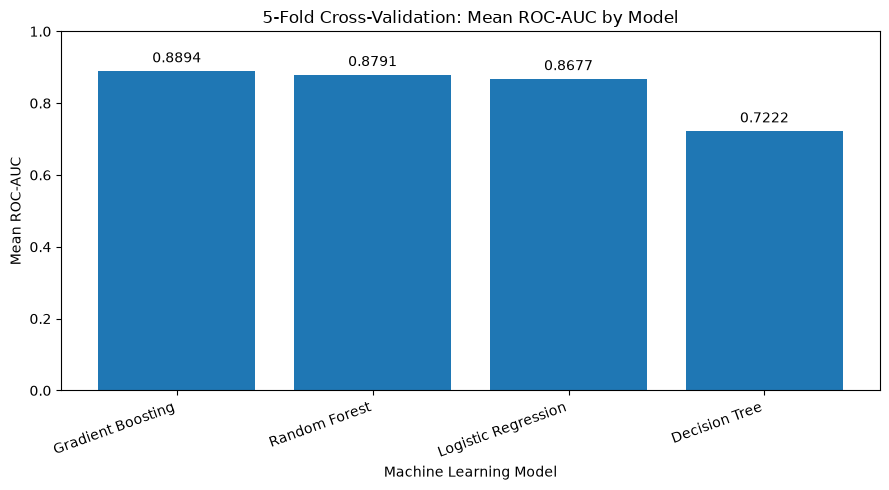

In [122]:
# Step 5.9.2 — Visualize Mean ROC-AUC by Model

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    cv_results_df["Model"],
    cv_results_df["Mean ROC-AUC"]
)

plt.title("5-Fold Cross-Validation: Mean ROC-AUC by Model")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")

# Display the ROC-AUC value above each bar.
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.015,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

### Step 5.9.2 — Visual Comparison of Model Performance

The ROC-AUC comparison shows that **Gradient Boosting** achieved the highest mean ROC-AUC of **0.8894**, followed by Random Forest (0.8791), Logistic Regression (0.8677), and Decision Tree (0.7222). Gradient Boosting performed best at distinguishing approved from declined applications across different classification thresholds, while Decision Tree showed the weakest discrimination. Based on these cross-validation results, Gradient Boosting is the leading candidate for final evaluation, although its predictive improvement must be weighed against the need for explainability in credit decisions.

Selected Model: Gradient Boosting
Test Accuracy:  0.8042
Test Precision (Declined): 0.8177
Test Recall (Declined):    0.7511
Test ROC-AUC:   0.8848

Confusion Matrix:
[[1082  189]
 [ 281  848]]

Classification Report:
              precision    recall  f1-score   support

    Approved       0.79      0.85      0.82      1271
    Declined       0.82      0.75      0.78      1129

    accuracy                           0.80      2400
   macro avg       0.81      0.80      0.80      2400
weighted avg       0.81      0.80      0.80      2400



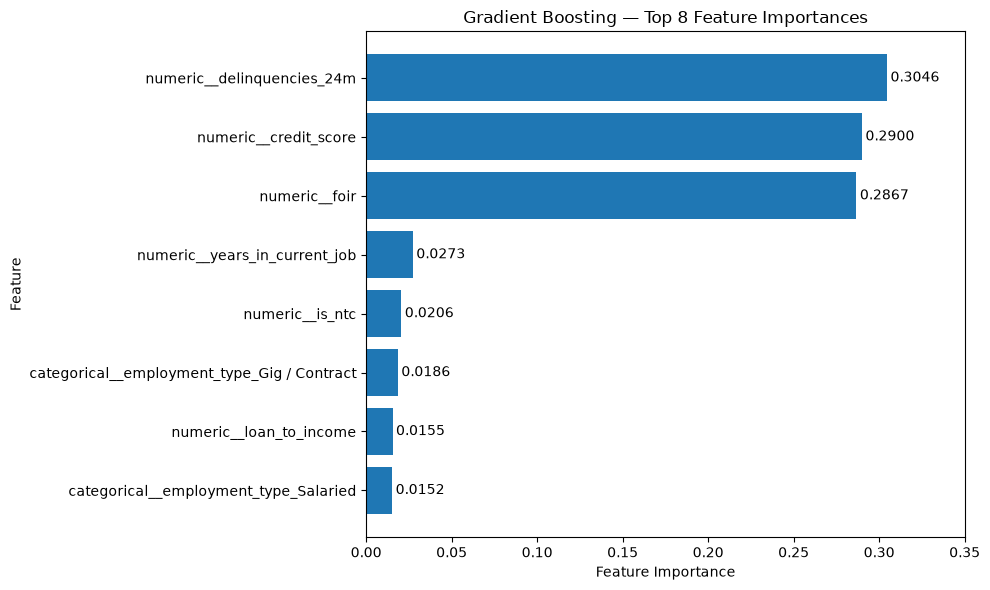


Top 8 Feature Importances:


,Feature,Importance
0,numeric__delinquencies_24m,0.3046
1,numeric__credit_score,0.2900
2,numeric__foir,0.2867
3,numeric__years_in_current_job,0.0273
4,numeric__is_ntc,0.0206
5,categorical__employment_type_Gig / Contract,0.0186
6,numeric__loan_to_income,0.0155
7,categorical__employment_type_Salaried,0.0152


In [123]:
# Step 5.9.3 — Evaluate Gradient Boosting on the Test Set

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create and train the selected model pipeline
selected_pipeline = clone(credit_pipeline)

selected_pipeline.set_params(
    classifier=GradientBoostingClassifier(random_state=42)
)

selected_pipeline.fit(X_train_raw, y_train)

# 2. Evaluate the model on the held-out test set
y_test_pred = selected_pipeline.predict(X_test_raw)
y_test_proba = selected_pipeline.predict_proba(X_test_raw)[:, 1]

print("Selected Model: Gradient Boosting")
print(f"Test Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(
    f"Test Precision (Declined): "
    f"{precision_score(y_test, y_test_pred, pos_label=1, zero_division=0):.4f}"
)
print(
    f"Test Recall (Declined):    "
    f"{recall_score(y_test, y_test_pred, pos_label=1, zero_division=0):.4f}"
)
print(f"Test ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}")

# 3. Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

# 4. Display the classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Approved", "Declined"],
        zero_division=0
    )
)

# 5. Extract feature names and importance scores
feature_names = (
    selected_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importances = (
    selected_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# 6. Select the eight most important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

top_8_features = (
    importance_df.head(8)
    .sort_values(by="Importance", ascending=True)
)

# 7. Plot the top eight features with values beside the bars
plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_8_features["Feature"],
    top_8_features["Importance"]
)

plt.title("Gradient Boosting — Top 8 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

# Add numerical importance values at the end of each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        va="center",
        ha="left"
    )

# Leave enough space for the numerical labels
plt.xlim(
    0,
    top_8_features["Importance"].max() * 1.15
)

plt.tight_layout()
plt.show()

# 8. Display the top eight feature importance values
print("\nTop 8 Feature Importances:")

display(
    importance_df.head(8).style.format({
        "Importance": "{:.4f}"
    })
)

### Step 5.9.3 — Final Model Evaluation and Feature Importance

Gradient Boosting was selected because it achieved the highest mean ROC-AUC (**0.8894**) during five-fold cross-validation. On the held-out test set, it achieved **80.42% accuracy**, **81.77% precision** for declined applications, **75.11% recall** for declined applications, and a **0.8848 ROC-AUC**. The three most important features were recent delinquencies (0.3046), credit score (0.2900), and FOIR (0.2867), together accounting for approximately **88.14%** of the model's total feature importance. Although Gradient Boosting performed better than Logistic Regression in cross-validation, it is less straightforward to interpret, which is important in credit decisions. Feature-importance analysis, additional explainability methods, and human oversight should support its use rather than treating model predictions as the sole basis for lending decisions.

---------------------------------------------------------------------------------------------------------------------

### Step 5.9 — Model Comparison and Selection

Gradient Boosting was selected because it achieved the highest mean ROC-AUC (**0.8894**) during five-fold cross-validation, compared with **0.8677** for Logistic Regression. It also achieved the highest mean accuracy (**79.86%**) and precision for the Declined class (**81.07%**) among the four models evaluated. On the held-out test set, Gradient Boosting achieved **80.42% accuracy**, **81.77% precision** for declined applications, **75.11% recall** for declined applications, and a **0.8848 ROC-AUC**.

The improvement over Logistic Regression is meaningful, but it must be weighed against the reduced interpretability of Gradient Boosting in credit decisions. Logistic Regression provides more direct coefficient-based explanations, whereas Gradient Boosting combines multiple decision trees and is harder to interpret. Therefore, Gradient Boosting is a promising candidate for decision support, provided the bank supplements it with suitable explainability methods, fairness monitoring, and human oversight rather than relying on its predictions alone.

The feature-importance analysis identified **delinquencies in the last 24 months (0.3046)**, **credit score (0.2900)**, and **FOIR (0.2867)** as the three most important features, together accounting for approximately **88.14%** of total feature importance. These results highlight the model's reliance on repayment history, creditworthiness, and repayment affordability. The findings should be compared with the historical approval patterns and feature analysis from Steps 5.2 and 5.3 to determine whether the model reinforces the patterns observed in the dataset. Feature importance indicates how the model uses features for prediction; it does not establish causation or prove that the historical decisions were fair.

--------------------------------------------------------------------------------------------------------------------

# 5.10  Design the two-lane pre-screener

In [124]:
# Step 5.10.1 — Prepare Approval Probabilities for Both Models

import numpy as np
import pandas as pd

# Convert predicted decline probabilities into approval probabilities.
# Target encoding: 1 = Declined, 0 = Approved.
# Therefore, P(Approved) = 1 - P(Declined).

# Gradient Boosting approval probabilities
gb_approval_proba = 1 - selected_pipeline.predict_proba(X_test_raw)[:, 1]

# Logistic Regression baseline approval probabilities
logistic_approval_proba = 1 - credit_pipeline.predict_proba(X_test_raw)[:, 1]

# Actual historical outcomes: True means Approved
actual_approved = (y_test == 0).to_numpy()

# Actual historical outcomes: True means Declined
actual_declined = (y_test == 1).to_numpy()

# Confirm probability arrays align with the test set
assert len(gb_approval_proba) == len(y_test)
assert len(logistic_approval_proba) == len(y_test)
assert np.all((gb_approval_proba >= 0) & (gb_approval_proba <= 1))
assert np.all((logistic_approval_proba >= 0) & (logistic_approval_proba <= 1))

print("Approval probabilities prepared successfully.")
print(f"Test applications: {len(y_test):,}")
print(f"Gradient Boosting probabilities: {len(gb_approval_proba):,}")
print(f"Logistic Regression probabilities: {len(logistic_approval_proba):,}")
print(f"Historically Approved: {actual_approved.sum():,}")
print(f"Historically Declined: {actual_declined.sum():,}")

Approval probabilities prepared successfully.
Test applications: 2,400
Gradient Boosting probabilities: 2,400
Logistic Regression probabilities: 2,400
Historically Approved: 1,271
Historically Declined: 1,129


### Step 5.10.1 — Prepare Approval Probabilities for Both Models

Approval probabilities were generated for both the **Gradient Boosting** model and the **Logistic Regression baseline** using the 2,400 held-out test applications. Since the target is encoded as `1 = Declined` and `0 = Approved`, the approval probability was calculated as one minus the predicted probability of decline. The probability arrays were validated to ensure they contain valid values between 0 and 1 and align with the test set, which contains **1,271 historically approved** and **1,129 historically declined** applications. These probabilities will be used to investigate two automated decision lanes while reserving uncertain applications for analyst review.

In [125]:
# Step 5.10.2 — Find Safe Auto-Decline and Fast-Track Thresholds

import numpy as np
import pandas as pd

# Maximum permitted error rate for each automated lane
MAX_ERROR_RATE = 0.05

# Candidate approval-probability thresholds
thresholds = np.round(np.arange(0.05, 1.00, 0.01), 2)

safe_pairs = []

for decline_threshold in thresholds:
    # Auto-decline applications with approval probability below this threshold
    auto_decline_mask = gb_approval_proba < decline_threshold

    decline_count = int(auto_decline_mask.sum())

    if decline_count > 0:
        wrongly_declined = int(
            actual_approved[auto_decline_mask].sum()
        )
        wrong_decline_rate = wrongly_declined / decline_count
    else:
        wrong_decline_rate = np.nan

    # Auto-decline error rate must not exceed 5%
    if decline_count == 0 or wrong_decline_rate > MAX_ERROR_RATE:
        continue

    for fast_track_threshold in thresholds:
        # Fast-track applications with approval probability at or above this threshold
        fast_track_mask = gb_approval_proba >= fast_track_threshold

        fast_track_count = int(fast_track_mask.sum())

        # Thresholds must not overlap
        if decline_threshold > fast_track_threshold:
            continue

        if fast_track_count > 0:
            wrongly_fast_tracked = int(
                actual_declined[fast_track_mask].sum()
            )
            wrong_fast_track_rate = (
                wrongly_fast_tracked / fast_track_count
            )
        else:
            wrong_fast_track_rate = np.nan

        # Fast-track error rate must not exceed 5%
        if fast_track_count == 0 or wrong_fast_track_rate > MAX_ERROR_RATE:
            continue

        automated_count = decline_count + fast_track_count

        safe_pairs.append({
            "Auto-Decline Threshold": decline_threshold,
            "Fast-Track Threshold": fast_track_threshold,
            "Auto-Declined": decline_count,
            "Wrongly Declined": wrongly_declined,
            "Wrong-Decline Rate": wrong_decline_rate,
            "Fast-Tracked": fast_track_count,
            "Wrongly Fast-Tracked": wrongly_fast_tracked,
            "Wrong Fast-Track Rate": wrong_fast_track_rate,
            "Total Automated": automated_count,
            "Sent to Review": len(y_test) - automated_count
        })

# Rank safe threshold pairs by the number of applications automated
safe_pairs_df = pd.DataFrame(safe_pairs)

if safe_pairs_df.empty:
    print("No threshold pairs satisfied both 5% risk limits.")
    print("We may need to evaluate alternative threshold values.")
else:
    safe_pairs_df = safe_pairs_df.sort_values(
        by=["Total Automated", "Auto-Declined"],
        ascending=[False, False]
    ).reset_index(drop=True)

    print("Number of safe threshold pairs:", len(safe_pairs_df))
    print("\nTop 10 threshold pairs:")
    
    display(
        safe_pairs_df.head(10).style.format({
            "Auto-Decline Threshold": "{:.2f}",
            "Fast-Track Threshold": "{:.2f}",
            "Wrong-Decline Rate": "{:.2%}",
            "Wrong Fast-Track Rate": "{:.2%}"
        })
    )

Number of safe threshold pairs: 117

Top 10 threshold pairs:


,Auto-Decline Threshold,Fast-Track Threshold,Auto-Declined,Wrongly Declined,Wrong-Decline Rate,Fast-Tracked,Wrongly Fast-Tracked,Wrong Fast-Track Rate,Total Automated,Sent to Review
0,0.17,0.89,584,28,4.79%,457,22,4.81%,1041,1359
1,0.16,0.89,565,27,4.78%,457,22,4.81%,1022,1378
2,0.15,0.89,547,23,4.20%,457,22,4.81%,1004,1396
3,0.17,0.90,584,28,4.79%,415,15,3.61%,999,1401
4,0.14,0.89,528,20,3.79%,457,22,4.81%,985,1415
5,0.16,0.90,565,27,4.78%,415,15,3.61%,980,1420
6,0.17,0.91,584,28,4.79%,389,14,3.60%,973,1427
7,0.13,0.89,510,18,3.53%,457,22,4.81%,967,1433
8,0.15,0.90,547,23,4.20%,415,15,3.61%,962,1438
9,0.16,0.91,565,27,4.78%,389,14,3.60%,954,1446


### Step 5.10.2 — Safe Threshold Selection

A threshold search identified **117 valid threshold pairs** that satisfied the maximum 5% error-rate requirement for both automated decision lanes. The selected pair uses an auto-decline threshold of **0.17** and a fast-track threshold of **0.89**. On the test set, 584 applications were auto-declined, with 4.79% historically approved, while 457 applications were fast-tracked, with 4.81% historically declined. Together, these lanes handled **1,041 applications (43.38%)**, leaving **1,359 applications (56.63%)** for analyst review. These results demonstrate a potential reduction in manual workload while respecting the specified risk limits on the evaluated test data.

In [126]:
# Step 5.10.3 — Compare Two-Lane Thresholds for Both Models

def find_safe_threshold_pairs(approval_probabilities, actual_approved, actual_declined):
    thresholds = np.round(np.arange(0.05, 1.00, 0.01), 2)
    results = []

    for decline_threshold in thresholds:
        auto_decline_mask = approval_probabilities < decline_threshold
        decline_count = int(auto_decline_mask.sum())

        if decline_count == 0:
            continue

        wrongly_declined = int(actual_approved[auto_decline_mask].sum())
        wrong_decline_rate = wrongly_declined / decline_count

        if wrong_decline_rate > 0.05:
            continue

        for fast_threshold in thresholds:
            if fast_threshold <= decline_threshold:
                continue

            fast_mask = approval_probabilities >= fast_threshold
            fast_count = int(fast_mask.sum())

            if fast_count == 0:
                continue

            wrongly_fast_tracked = int(actual_declined[fast_mask].sum())
            wrong_fast_rate = wrongly_fast_tracked / fast_count

            if wrong_fast_rate > 0.05:
                continue

            total_automated = decline_count + fast_count

            results.append({
                "Auto-Decline Threshold": decline_threshold,
                "Fast-Track Threshold": fast_threshold,
                "Auto-Declined": decline_count,
                "Wrong-Decline Rate": wrong_decline_rate,
                "Fast-Tracked": fast_count,
                "Wrong Fast-Track Rate": wrong_fast_rate,
                "Total Automated": total_automated,
                "Sent to Review": len(approval_probabilities) - total_automated
            })

    results_df = pd.DataFrame(results)

    if results_df.empty:
        return results_df

    return results_df.sort_values(
        ["Total Automated", "Auto-Declined"],
        ascending=[False, False]
    ).reset_index(drop=True)


gb_safe_pairs = find_safe_threshold_pairs(
    gb_approval_proba, actual_approved, actual_declined
)

logistic_safe_pairs = find_safe_threshold_pairs(
    logistic_approval_proba, actual_approved, actual_declined
)

if not gb_safe_pairs.empty and not logistic_safe_pairs.empty:
    policy_comparison = pd.DataFrame([
        {
            "Model": "Gradient Boosting",
            **gb_safe_pairs.iloc[0].to_dict()
        },
        {
            "Model": "Logistic Regression",
            **logistic_safe_pairs.iloc[0].to_dict()
        }
    ])

    print("Best safe threshold pair for each model:")
    display(policy_comparison.style.format({
        "Auto-Decline Threshold": "{:.2f}",
        "Fast-Track Threshold": "{:.2f}",
        "Wrong-Decline Rate": "{:.2%}",
        "Wrong Fast-Track Rate": "{:.2%}"
    }))
else:
    print("At least one model has no threshold pair satisfying both risk limits.")
    print("Gradient Boosting safe pairs:", len(gb_safe_pairs))
    print("Logistic Regression safe pairs:", len(logistic_safe_pairs))

Best safe threshold pair for each model:


,Model,Auto-Decline Threshold,Fast-Track Threshold,Auto-Declined,Wrong-Decline Rate,Fast-Tracked,Wrong Fast-Track Rate,Total Automated,Sent to Review
0,Gradient Boosting,0.17,0.89,584.000000,4.79%,457.000000,4.81%,1041.000000,1359.000000
1,Logistic Regression,0.10,0.89,363.000000,4.68%,405.000000,4.94%,768.000000,1632.000000


### Step 5.10.3 — Comparison of Two-Lane Decision Policies

Gradient Boosting automated **1,041 applications (43.38%)**, compared with **768 applications (32.00%)** for Logistic Regression, while both models satisfied the specified maximum 5% error-rate limits for auto-decline and fast-track decisions on the test set. Gradient Boosting therefore automated **273 additional applications**, reducing the number sent to analyst review from 1,632 to 1,359. Logistic Regression had slightly lower error rates in both automated lanes, but Gradient Boosting handled more applications automatically. These results suggest that Gradient Boosting could provide greater operational efficiency, provided its lower interpretability is addressed through explainability methods, validation, and human oversight. Since the thresholds were explored on the test set, they should be reselected using validation data and assessed on an untouched test set before deployment.

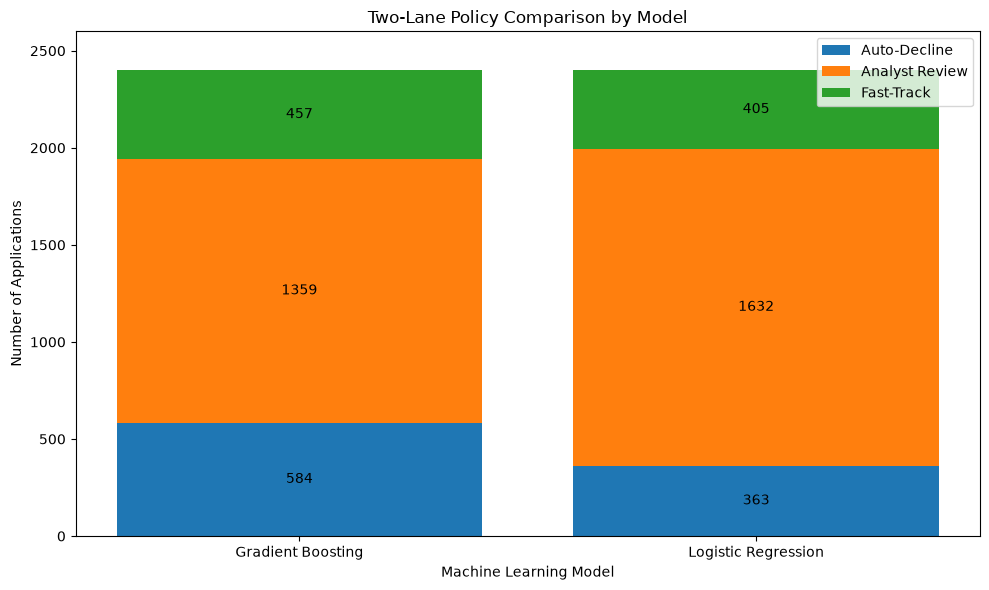

Gradient Boosting: 2,400 applications
Logistic Regression: 2,400 applications

Validation passed: all test applications are accounted for.


In [127]:
# Step 5.10.4 — Stacked Bar Chart: Two-Lane Policy Comparison

import matplotlib.pyplot as plt
import numpy as np

# Model names
model_names = ["Gradient Boosting", "Logistic Regression"]

# Retrieve the best safe threshold results for each model
gb_policy = gb_safe_pairs.iloc[0]
logistic_policy = logistic_safe_pairs.iloc[0]

# Application counts for each decision lane
auto_declined_counts = [
    int(gb_policy["Auto-Declined"]),
    int(logistic_policy["Auto-Declined"])
]

review_counts = [
    int(gb_policy["Sent to Review"]),
    int(logistic_policy["Sent to Review"])
]

fast_tracked_counts = [
    int(gb_policy["Fast-Tracked"]),
    int(logistic_policy["Fast-Tracked"])
]

# Create the stacked bar chart
plt.figure(figsize=(10, 6))

bars_declined = plt.bar(
    model_names,
    auto_declined_counts,
    label="Auto-Decline"
)

bars_review = plt.bar(
    model_names,
    review_counts,
    bottom=auto_declined_counts,
    label="Analyst Review"
)

stack_bottom = np.array(auto_declined_counts) + np.array(review_counts)

bars_fast_track = plt.bar(
    model_names,
    fast_tracked_counts,
    bottom=stack_bottom,
    label="Fast-Track"
)

# Add counts inside each segment
for bars in [bars_declined, bars_review, bars_fast_track]:
    for bar in bars:
        height = bar.get_height()

        if height > 0:
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + height / 2,
                f"{int(height)}",
                ha="center",
                va="center"
            )

plt.title("Two-Lane Policy Comparison by Model")
plt.xlabel("Machine Learning Model")
plt.ylabel("Number of Applications")
plt.ylim(0, 2600)
plt.legend()
plt.tight_layout()
plt.show()

# Validate that each model accounts for all test applications
for i, model_name in enumerate(model_names):
    total = (
        auto_declined_counts[i]
        + review_counts[i]
        + fast_tracked_counts[i]
    )

    print(f"{model_name}: {total:,} applications")

    assert total == len(y_test), (
        f"Lane counts do not sum to the test-set size for {model_name}."
    )

print("\nValidation passed: all test applications are accounted for.")

### Step 5.10 — Two-Lane Policy and Monthly Business Impact

The threshold search identified a Gradient Boosting policy with an auto-decline threshold of **0.17** and a fast-track threshold of **0.89**, compared with **0.10** and **0.89**, respectively, for Logistic Regression. Both models satisfied the specified maximum **5% error-rate limits** for the two automated lanes on the evaluated test set. Gradient Boosting automated **1,041 of 2,400 applications (43.38%)**, compared with **768 (32.00%)** for Logistic Regression, reducing the analyst-review queue by **273 applications** in the test set.

At a monthly volume of 3,000 applications, these test-set proportions correspond to approximately **1,301 applications automated by Gradient Boosting** and **960 by Logistic Regression**. This represents approximately **341 additional applications** removed from full manual review each month, equivalent to around **142 analyst hours saved per month**, assuming each application removed from full manual review saves 25 minutes. These figures are estimates based on test-set proportions; the thresholds should be validated on separate data before deployment, and any lighter checks required for fast-tracked applications should be accounted for when estimating actual savings.

--------------------------------------------------------------------------------------------------------------------------------

# Step 5.11 — Credit Policy Recommendation

I recommend **Gradient Boosting** as the preferred pre-screening model, using an auto-decline threshold of **0.17** and a fast-track threshold of **0.89**, because it achieved a cross-validated ROC-AUC of **0.8894** and automated more applications than Logistic Regression while meeting both 5% lane error limits on the evaluated test set. Under this policy, approximately **24.33%** of applications would be auto-declined, **56.63%** would be sent for analyst review, and **19.04%** would be fast-tracked; these proportions are based on the 2,400-application test set. At a monthly volume of 3,000 applications, Gradient Boosting could automate approximately **1,301 applications**, compared with **960** under Logistic Regression, potentially reducing the full manual-review queue by about **341 applications and 142 analyst hours per month**, assuming 25 minutes saved per application removed from full review. The main risk of going live is that historical decisions may contain biases or patterns that do not generalise to future applicants, and the model may wrongly decline creditworthy customers or fast-track applicants who would be declined after full review. Applications with missing or limited credit history, borderline scores, unusual financial circumstances, or cases flagged by fairness and risk controls should remain with a human analyst rather than being decided solely by the model. The bank should monitor approval and decline outcomes, lane error rates, and auto-decline and fast-track rates across gender and employment groups, investigate material disparities, and avoid using gender as a decision feature while recognising that proxy variables may still create unfair outcomes. Before a full rollout, I recommend a **time-limited shadow pilot** in which model recommendations are recorded alongside normal analyst decisions, allowing the bank to validate both 5% error limits, fairness across applicant groups, and actual analyst-time savings on new applications.

# Step 5.12 — Stretch: Where does the model struggle? 

In [128]:
# Step 5.12.1 — Prepare Applicant Features for K-Means Clustering

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Features specified by the assignment
cluster_features = [
    "monthly_income",
    "credit_score",
    "foir",
    "years_in_current_job",
    "age"
]

# Use the raw data, then engineer FOIR using the fitted feature engineer
X_cluster_raw = raw_train[[
    "monthly_income",
    "credit_score",
    "existing_emi",
    "proposed_emi",
    "years_in_current_job",
    "age"
]].copy()

X_cluster_raw["foir"] = (
    (X_cluster_raw["existing_emi"] + X_cluster_raw["proposed_emi"])
    / X_cluster_raw["monthly_income"].replace(0, np.nan)
)

X_cluster = X_cluster_raw[cluster_features].copy()

# Impute missing values and scale using training data only
cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()

X_cluster_imputed = cluster_imputer.fit_transform(X_cluster)
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster_imputed)

print("Clustering data prepared successfully.")
print("Training applications:", X_cluster_scaled.shape[0])
print("Clustering features:", cluster_features)
print("Missing values after imputation:", np.isnan(X_cluster_imputed).sum())

Clustering data prepared successfully.
Training applications: 9600
Clustering features: ['monthly_income', 'credit_score', 'foir', 'years_in_current_job', 'age']
Missing values after imputation: 0


### Step 5.12.1 — Prepare Applicant Data for Clustering

Five numerical features—**monthly income, credit score, FOIR, years in the current job, and age**—were selected to identify groups of applicants with similar financial and demographic characteristics. Missing values were replaced using median imputation, and the features were standardized using `StandardScaler` because K-Means is sensitive to differences in feature scales. The imputer and scaler were fitted using only the training data to avoid introducing information from the test set into preprocessing.

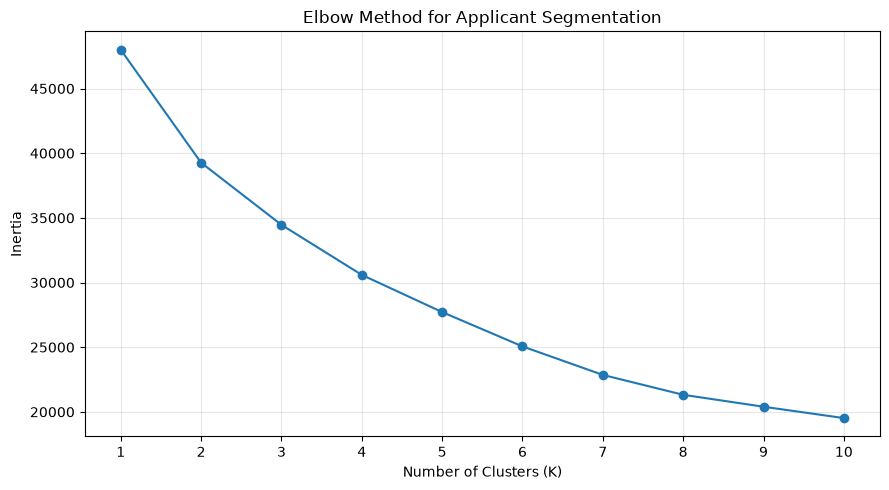

In [129]:
# Step 5.12.2 — Elbow Method to Select the Number of Clusters

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Applicant Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Step 5.12.2 — Selecting the Number of Clusters

The elbow method was used to identify a suitable number of clusters by comparing inertia values for **K = 1 through K = 10**. The plot shows a substantial reduction in inertia at smaller values of K, followed by progressively smaller improvements as the number of clusters increases. Although the elbow is not sharply defined, **K = 3** was selected as a reasonable balance between segment separation and model simplicity.

In [130]:
# Step 5.12.3 — Fit K-Means and Profile Applicant Clusters

from sklearn.cluster import KMeans
import pandas as pd

# Fit K-Means using the selected number of clusters
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

train_clusters = kmeans_model.fit_predict(X_cluster_scaled)

# Attach cluster labels to the training data for analysis only
cluster_profile_data = X_cluster.copy()
cluster_profile_data["Cluster"] = train_clusters
cluster_profile_data["Decision"] = raw_train["decision"].to_numpy()

# Summarize segment characteristics
cluster_profile = cluster_profile_data.groupby("Cluster").agg(
    Application_Count=("Cluster", "size"),
    Average_Monthly_Income=("monthly_income", "mean"),
    Average_Credit_Score=("credit_score", "mean"),
    Average_FOIR=("foir", "mean"),
    Average_Job_Tenure=("years_in_current_job", "mean"),
    Average_Age=("age", "mean"),
    Approval_Rate=("Decision", lambda x: (x == "Approved").mean())
).reset_index()

display(cluster_profile.style.format({
    "Average_Monthly_Income": "{:,.2f}",
    "Average_Credit_Score": "{:.2f}",
    "Average_FOIR": "{:.3f}",
    "Average_Job_Tenure": "{:.2f}",
    "Average_Age": "{:.2f}",
    "Approval_Rate": "{:.2%}"
}))

print("\nTotal applications profiled:", cluster_profile["Application_Count"].sum())

,Cluster,Application_Count,Average_Monthly_Income,Average_Credit_Score,Average_FOIR,Average_Job_Tenure,Average_Age,Approval_Rate
0,0,4956,"50,194.74",715.74,0.279,2.34,29.13,54.58%
1,1,3003,"79,162.78",740.13,0.297,6.49,39.37,67.37%
2,2,1641,"56,934.49",728.15,0.673,3.19,33.77,21.57%



Total applications profiled: 9600


### Step 5.12.3 — Applicant Cluster Profiles

K-Means grouped the 9,600 training applications into three segments with distinct financial characteristics and historical approval rates. **Cluster 0 — Moderate-Income Applicants** contains 4,956 applications, with an average monthly income of ₹50,194.74 and an approval rate of 54.58%. **Cluster 1 — Higher-Income, Established Applicants** contains 3,003 applications and has the highest average monthly income (₹79,162.78), credit score (740.13), job tenure (6.49 years), and approval rate (67.37%). **Cluster 2 — High Repayment-Burden Applicants** contains 1,641 applications and has the highest average FOIR (0.673) and lowest approval rate (21.57%), suggesting that repayment affordability warrants closer examination. These labels summarize group-level patterns and should not be used as standalone lending decisions.

In [131]:
# Step 5.12.4 — Evaluate Gradient Boosting Errors by Applicant Cluster

# Prepare the five clustering features for the held-out test set
X_test_cluster_raw = raw_test[
    [
        "monthly_income",
        "credit_score",
        "existing_emi",
        "proposed_emi",
        "years_in_current_job",
        "age"
    ]
].copy()

# Calculate FOIR using the same definition as the training data
X_test_cluster_raw["foir"] = (
    (
        X_test_cluster_raw["existing_emi"]
        + X_test_cluster_raw["proposed_emi"]
    )
    / X_test_cluster_raw["monthly_income"].replace(0, np.nan)
)

X_test_cluster = X_test_cluster_raw[cluster_features].copy()

# Apply the already-fitted training imputer and scaler
X_test_cluster_imputed = cluster_imputer.transform(X_test_cluster)
X_test_cluster_scaled = cluster_scaler.transform(X_test_cluster_imputed)

# Assign test applications to the existing training clusters
test_clusters = kmeans_model.predict(X_test_cluster_scaled)

# Use the previously evaluated Gradient Boosting predictions
cluster_error_data = pd.DataFrame({
    "Cluster": test_clusters,
    "Actual_Decision": np.asarray(y_test),
    "Predicted_Decision": np.asarray(y_test_pred)
})

# Calculate segment size, approval rate, and model error rate
cluster_error_data["Actual_Approved"] = (
    cluster_error_data["Actual_Decision"] == 0
)

cluster_error_data["Model_Error"] = (
    cluster_error_data["Actual_Decision"]
    != cluster_error_data["Predicted_Decision"]
)

cluster_test_profile = cluster_error_data.groupby("Cluster").agg(
    Application_Count=("Cluster", "size"),
    Actual_Approval_Rate=("Actual_Approved", "mean"),
    Model_Error_Rate=("Model_Error", "mean"),
    Model_Errors=("Model_Error", "sum")
).reset_index()

display(cluster_test_profile.style.format({
    "Actual_Approval_Rate": "{:.2%}",
    "Model_Error_Rate": "{:.2%}"
}))

print("\nTotal test applications profiled:",
      cluster_test_profile["Application_Count"].sum())

,Cluster,Application_Count,Actual_Approval_Rate,Model_Error_Rate,Model_Errors
0,0,1216,54.28%,20.48%,249
1,1,746,68.50%,20.64%,154
2,2,438,22.83%,15.30%,67



Total test applications profiled: 2400


### Step 5.12.4 — Model Errors by Applicant Segment

Gradient Boosting was evaluated across the three applicant clusters in the held-out test set. Cluster 1 had the highest overall model error rate (**20.64%**, or 154 errors among 746 applications), followed closely by Cluster 0 (**20.48%**, or 249 errors among 1,216 applications). Cluster 2 had the lowest error rate (**15.30%**, or 67 errors among 438 applications), but also had the lowest actual approval rate at 22.83%. Because the overall error rate combines false approvals and false declines, it does not establish which segment presents the greatest risk on its own. These results support further investigation of errors within each segment, with human review retained for uncertain or potentially high-impact cases rather than using cluster membership as an automatic lending decision.

In [132]:
# Step 5.12.5 — Examine False Declines and False Approvals by Cluster

cluster_error_data["False_Decline"] = (
    (cluster_error_data["Actual_Decision"] == 0)
    & (cluster_error_data["Predicted_Decision"] == 1)
)

cluster_error_data["False_Approval"] = (
    (cluster_error_data["Actual_Decision"] == 1)
    & (cluster_error_data["Predicted_Decision"] == 0)
)

error_type_profile = cluster_error_data.groupby("Cluster").agg(
    Application_Count=("Cluster", "size"),
    False_Declines=("False_Decline", "sum"),
    False_Approvals=("False_Approval", "sum")
).reset_index()

error_type_profile["False_Decline_Rate"] = (
    error_type_profile["False_Declines"]
    / error_type_profile["Application_Count"]
)

error_type_profile["False_Approval_Rate"] = (
    error_type_profile["False_Approvals"]
    / error_type_profile["Application_Count"]
)

display(error_type_profile.style.format({
    "False_Decline_Rate": "{:.2%}",
    "False_Approval_Rate": "{:.2%}"
}))

,Cluster,Application_Count,False_Declines,False_Approvals,False_Decline_Rate,False_Approval_Rate
0,0,1216,96,153,7.89%,12.58%
1,1,746,46,108,6.17%,14.48%
2,2,438,47,20,10.73%,4.57%


### Step 5.12.5 — Error Analysis and Human Review

The segment-level error analysis revealed different risks across the three applicant clusters. Cluster 1 had the highest false-approval rate (**14.48%**), while Cluster 2 had the highest false-decline rate (**10.73%**), indicating that the model may incorrectly approve some applications declined by the credit team and incorrectly decline some applications the team approved. Cluster 0 also showed substantial error rates, with 7.89% false declines and 12.58% false approvals. **Cluster 2 should receive particular attention for human review of potential declines**, because its false-decline rate is the highest and its average FOIR is elevated; however, high FOIR alone should not determine a lending decision. The bank should also retain human review for borderline predictions, uncertain cases, and applications flagged by risk or fairness controls. These safeguards can help reduce inappropriate automatic decisions while allowing the model to support, rather than replace, professional credit assessment.